---

# We try to approximate the $\mathrm{VIX}$ in the QRH model

---

In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats, integrate, linalg, optimize
import matplotlib as mpl
from numpy.polynomial.laguerre import laggauss


from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import var_swap_robust
import utils_vix


sns.set_theme("talk")
mpl.rcParams["figure.figsize"] = (8, 6)
SEED = 1234

Load market data and set initial forward variance curve

In [3]:
df_spx = pd.read_csv("spx_implied_vol_20230215.csv", index_col=0)
df_vix = pd.read_csv("vix_implied_vol_20230215.csv", index_col=0)
df_spx["Texp_days"] = (365.25 * df_spx["Texp"]).round().astype(int)
df_vix["Texp_days"] = (365.25 * df_vix["Texp"]).round().astype(int)
res_vs = var_swap_robust(ivol_data=df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.03)["xi_curve"]

/Users/florianbourgey/projects/QuadraticRoughHeston/utils.py:183: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


In [4]:
spx_expiries_days = [7, 14, 20, 28]
spx_expiries = np.array(spx_expiries_days) / 365.25

vix_expiries_days = [7, 14, 20, 28]
vix_expiries = np.array(vix_expiries_days) / 365.25

Set QRH parameters

In [5]:
params0 = {"al": 0.568, "lam": 9.68, "nu": 0.572, "c": 8.1e-3, "n_quad": 20}
qrh = QuadraticRoughHeston(**params0, xi0=xi_smooth)

In [6]:
paths = 3 * 10**5
steps = 300
qrh_sim = qrh.simulate(paths=paths, steps=steps, expiries=spx_expiries, output="all")

### Check distribution of $\chi_k$

Let us check the distribution of the 
$\chi_k = \int_{(k-1)\Delta}^{k\Delta} \sqrt{V_s} \, dW_s$
with $\Delta = T/n$

In [7]:
T = spx_expiries[0]
chi = qrh_sim[T]["chi"]
print(chi.shape)

(300, 200000)


In [8]:
Delta = T / steps

tmp_var = np.array(
    [
        integrate.quad(lambda u: qrh.xi0(u), (k - 1) * Delta, k * Delta)[0]
        for k in range(1, steps + 1)
    ]
)

PDF plot

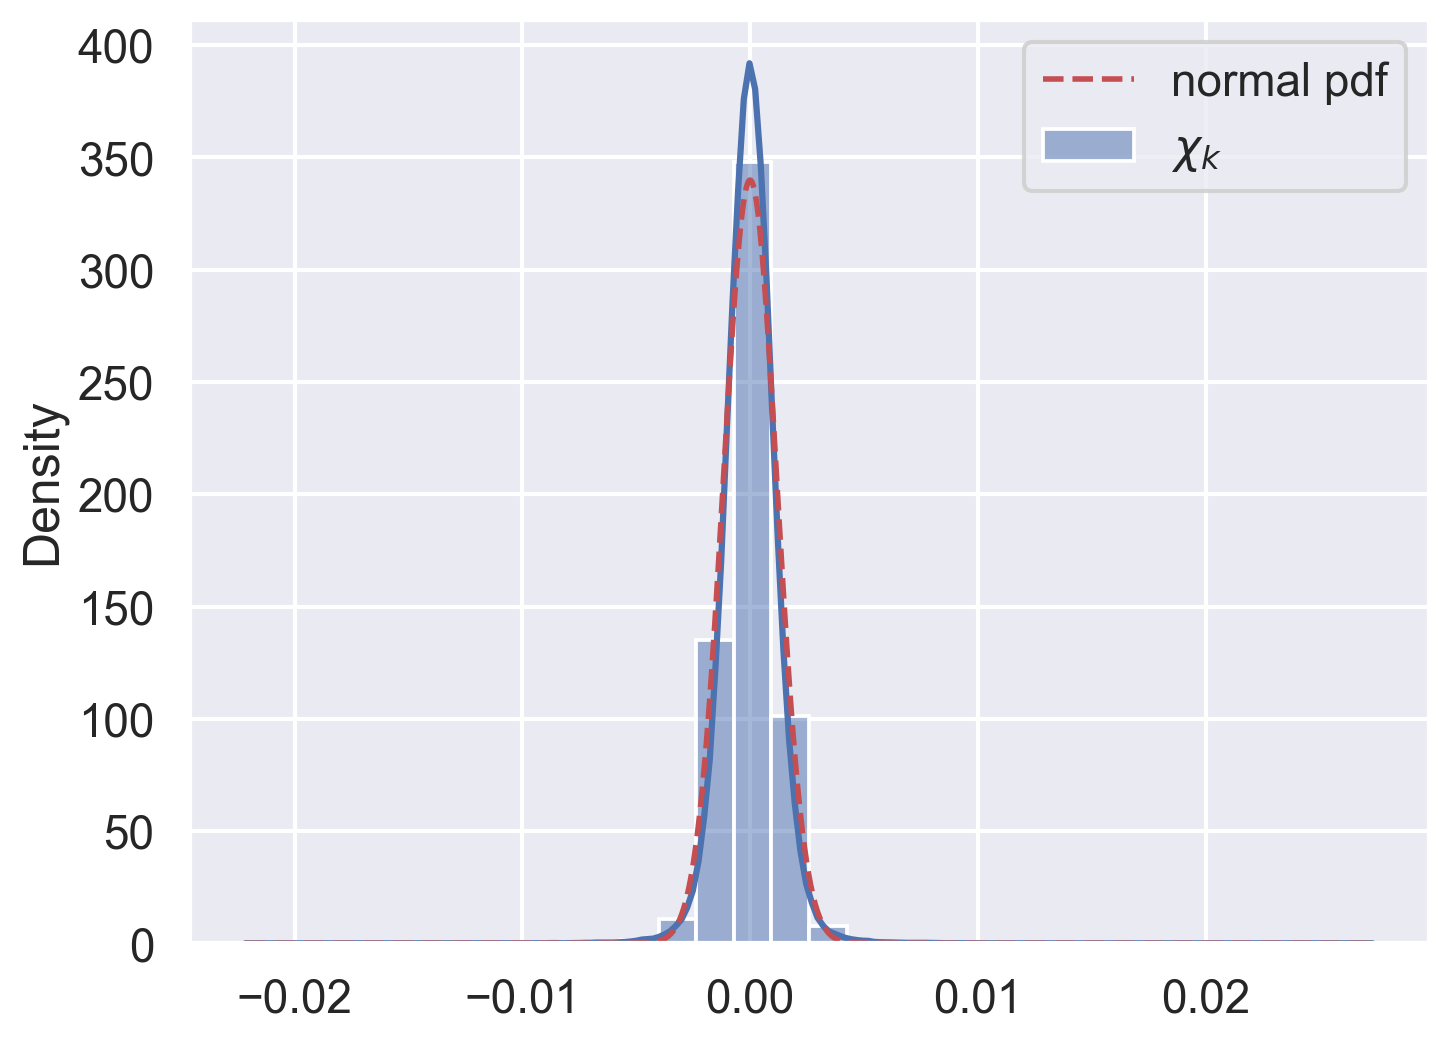

In [9]:
k = 200
chi_k = chi[100, :]
tab_x = np.linspace(chi_k.min(), chi_k.max(), 1000)
mean = chi_k.mean()
std = chi_k.std()

fig, ax = plt.subplots()
sns.histplot(chi_k, bins=30, kde=True, stat="density", ax=ax, label="$\\chi_k$")
ax.plot(
    tab_x, stats.norm.pdf(tab_x, loc=mean, scale=std), "r--", lw=2, label="normal pdf"
)
ax.legend()
plt.show()

Q-Q plot

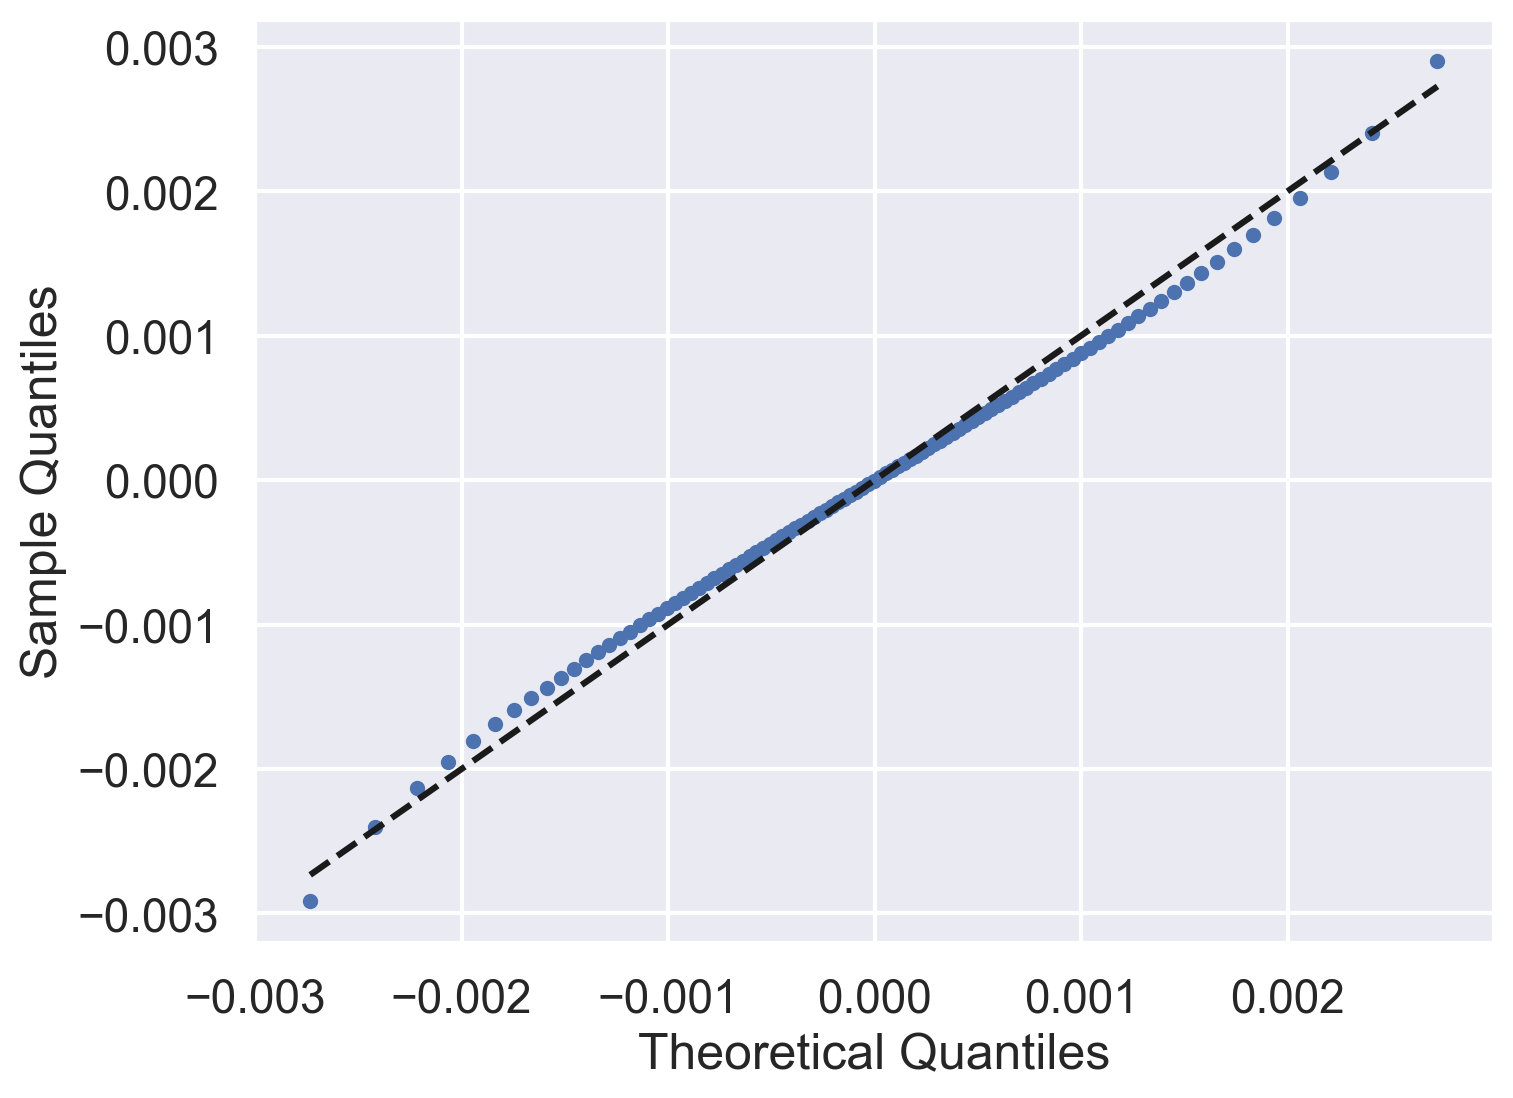

In [10]:
quantiles = np.linspace(1e-2, 1 - 1e-2, 101)
chi_k_quantiles = np.quantile(chi_k, q=quantiles)
normal_quantiles = stats.norm.ppf(quantiles, loc=mean, scale=std)

fig, ax = plt.subplots()
ax.plot(normal_quantiles, chi_k_quantiles, ".")
ax.plot(normal_quantiles, normal_quantiles, "k--")
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
plt.show()

### Gaussian approximation

From the paper [The SSR under Quadratic Rough Heston](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5239929),
observe that 

$$
\mathrm{VIX}_T^2 \approx a_T + b_T^\top  \chi + \chi^\top C_T \chi
$$

where 

- $\chi = (\chi_i)_{1 \leq i \leq n}$ with 
$\chi_i = \int_{(i-1)\Delta}^{i\Delta} \sqrt{V_s} \, dW_s$

- $b_T = (b_{i}(T))_{1 \leq i \leq n}$ 

- $C_T = (c_{ij}(T))_{1 \leq i,j \leq n}$

and

$$
\begin{align*}
w(u) &= 1 + K_0(\delta - u) \\
a_T &= \frac{1}{\delta} \int_{0}^{\delta} \left( y_0(T+u)^2 + c \right) w(u) \, du \\
b_i(T) &= \frac{2}{\delta} \int_{0}^{\delta} y_0(T+u) \, a_i(T+u) \, w(u) \, du \\
c_{ij}(T) &= \frac{1}{\delta} \int_{0}^{\delta} a_i(T+u) \, a_j(T+u) \, w(u) \, du
\end{align*}
$$

We approximate the $(\chi_i)_{1 \leq i \leq n}$ as independent centered normal random variables
with variance $\mathrm{Var}(\chi_i) = \Delta \overline{\xi}_i$ 
where
$$
\overline{\xi}_i = \frac{1}{\Delta}\int_{(i-1)\Delta}^{i\Delta} \xi_0(u) \, du,
\qquad
i = 1, \ldots, n.
$$


**Characteristic function of quadratic normal**

Let $Z \sim \mathcal{N}(0, I_n)$ and $C \in \mathbb{R}^{n \times n}$ a positive semi-definite matrix. The characteristic function of the quadratic 
form $S = a + b^\top Z + Z^\top C Z$ is given by
$$
\varphi_S(t) 
= \mathbb{E}[e^{itS}]
= e^{i a t} \times \mathrm{det}(I_n - 2 i t C)^{-1/2} \times \exp\left( -\frac{t^2}{2} b^\top (I_n - 2 i t C)^{-1} b \right)
$$

Note that as $C$ is a covariance matrix, diagonalization gives
$$
    C = U \Lambda U^\top,
$$
with $U$ orthonormal and $\Lambda = \mathrm{diag}(\lambda_1, \ldots, \lambda_n)$
and $\lambda_i \geq 0$ for all $i$.

In particular, we have

$$
    (I_n - 2 i t C)^{-1} = U \mathrm{diag}\left(\frac{1}{1 - 2 i t \lambda_j}\right)_{j=1}^{n} U^\top
$$

and

$$
    \mathrm{det}(I_n - 2 i t C) = \prod_{j=1}^{n} (1 - 2 i t \lambda_j)
$$

Observe that
$$
\begin{align*}
    \varphi_S(it)
    &=
    \frac{e^{- a t}}{\mathrm{det}(I_n + 2 t C)^{-1/2}}
    \, \exp\left( \frac{t^2}{2} b^\top (I_n + 2 t C)^{-1} b \right)\\
    &=
    \frac{e^{- a t}}{\sqrt{\prod_{j=1}^{n} (1 + 2 t \lambda_j)}}
    \, \exp\left( \frac{t^2}{2} \sum_{j=1}^{n} 
    \frac{\tilde{b}_j^2}{1 + 2 t \lambda_j} \right)
\end{align*}
$$

---

To apply this to $\mathrm{VIX}_T^2$, we set $D=\Delta\times\mathrm{diag}(\overline{\xi}_1, \ldots, \overline{\xi}_n)$ and set $\chi = D^{1/2} Z$.

Then, replace $b$ with $D^{1/2} b_T$ and $C$ with $D^{1/2} C_T D^{1/2}$.

In [8]:
# pick expiry for VIX and store MC VIX values
expiry = spx_expiries[3]
vix_expiry_mc = qrh_sim[expiry]["vix"]

Pre-compute parameters: $a$, the vector $b$, and the matrix $C$

In [9]:
n_quad_vix = 10
a_scalar, b_vec, c_mat = utils_vix.vix2_approx_coefficients(
    qrh, expiry, steps=steps, n_quad_vix=n_quad_vix
)

Perform SVD on matrix $C$

In [10]:
U, D, U_t = linalg.svd(c_mat)
U_t_b = U_t @ b_vec

In [11]:
a_scalar

np.float64(0.03976635269976238)

Define characteristic function of VIX squared quadratic Gaussian approximation

Compare characteristic functions with and without SVD.

We plot $t \mapsto \varphi_{\text{VIX}_T^2}(it)$. 
This is a real-valued function.

In [14]:
ts = np.linspace(0.0, 200.0, 201)
phi_vix2_i_ts = np.array(
    [
        utils_vix.charfunc_quadratic_normal(t=1j * _t, a=a_scalar, b=b_vec, C=c_mat)
        for _t in ts
    ]
)
phi_vix2_i_ts_svd = np.array(
    [
        utils_vix.charfunc_quadratic_normal_svd(
            t=1j * _t, a=a_scalar, b=b_vec, U=U, D=D
        )
        for _t in ts
    ]
)

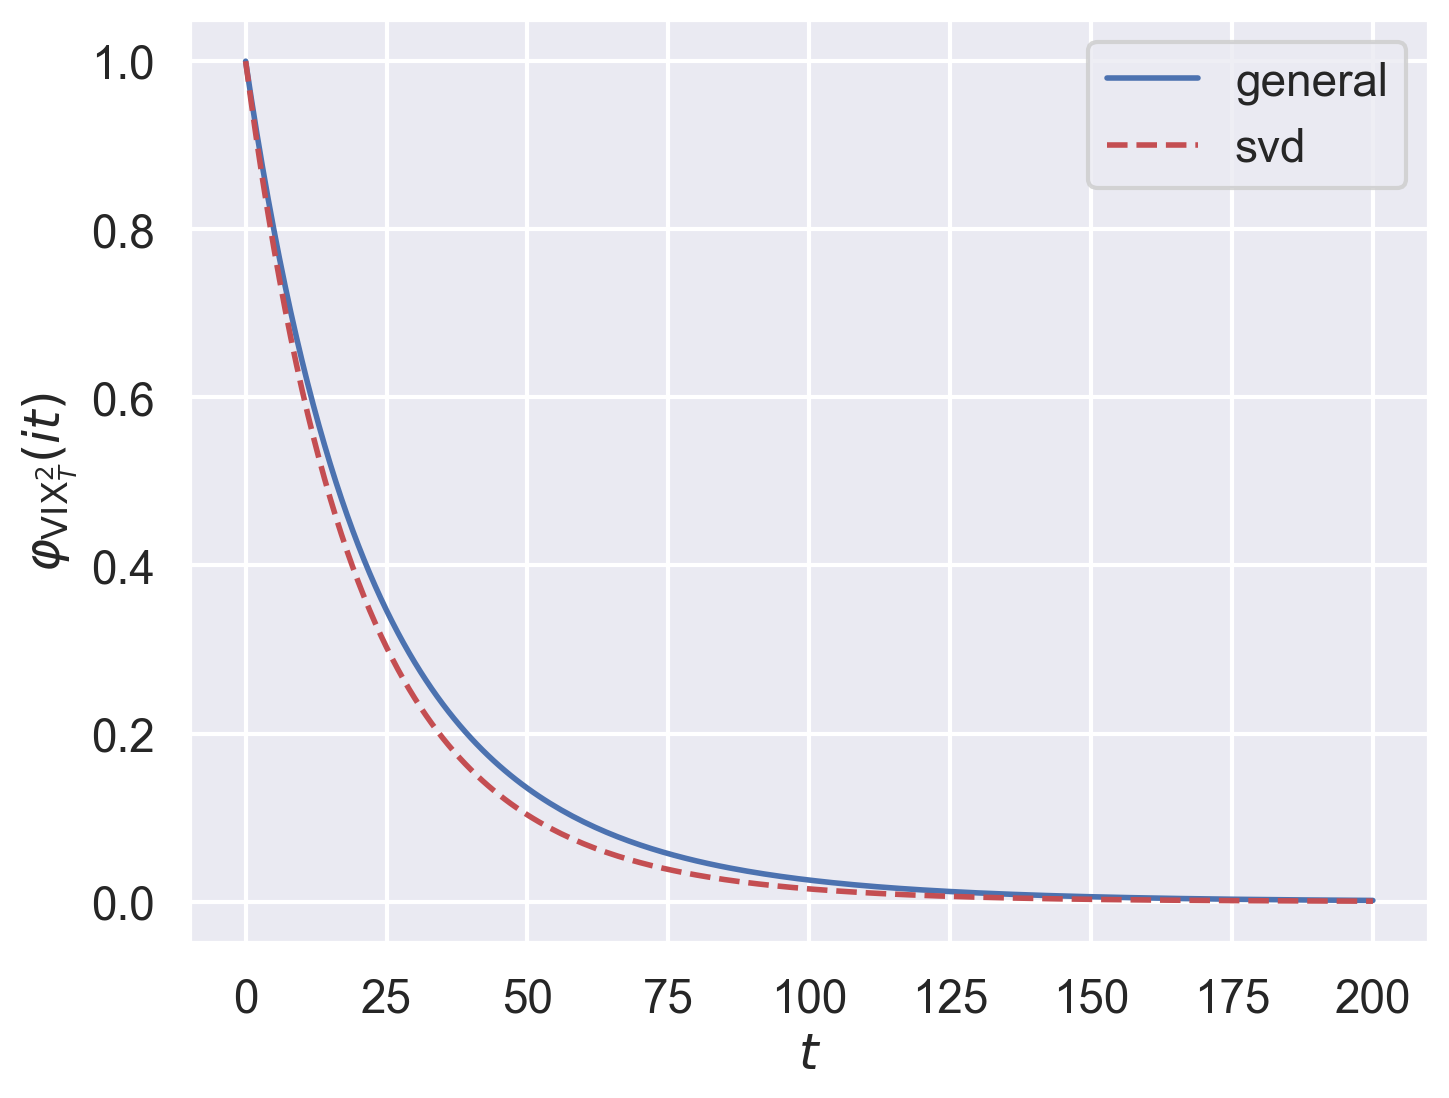

In [15]:
fig, ax = plt.subplots()
ax.plot(ts, np.real(phi_vix2_i_ts), "b-", lw=2, label="general")
ax.plot(ts, np.real(phi_vix2_i_ts_svd), "r--", lw=2, label="svd")
ax.set_xlabel("$t$")
ax.set_ylabel("$\\varphi_{\\mathrm{VIX}_T^2}(it)$")
ax.legend()
plt.show()

/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_86286/1864920488.py:2: RuntimeWarning: invalid value encountered in divide
  ax.plot(ts, (1 - np.real(phi_vix2_i_ts)) / ts ** (3 / 2), "b-", lw=2, label="general")
/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_86286/1864920488.py:3: RuntimeWarning: invalid value encountered in divide
  ax.plot(ts, (1 - np.real(phi_vix2_i_ts_svd)) / ts ** (3 / 2), "r--", lw=2, label="svd")


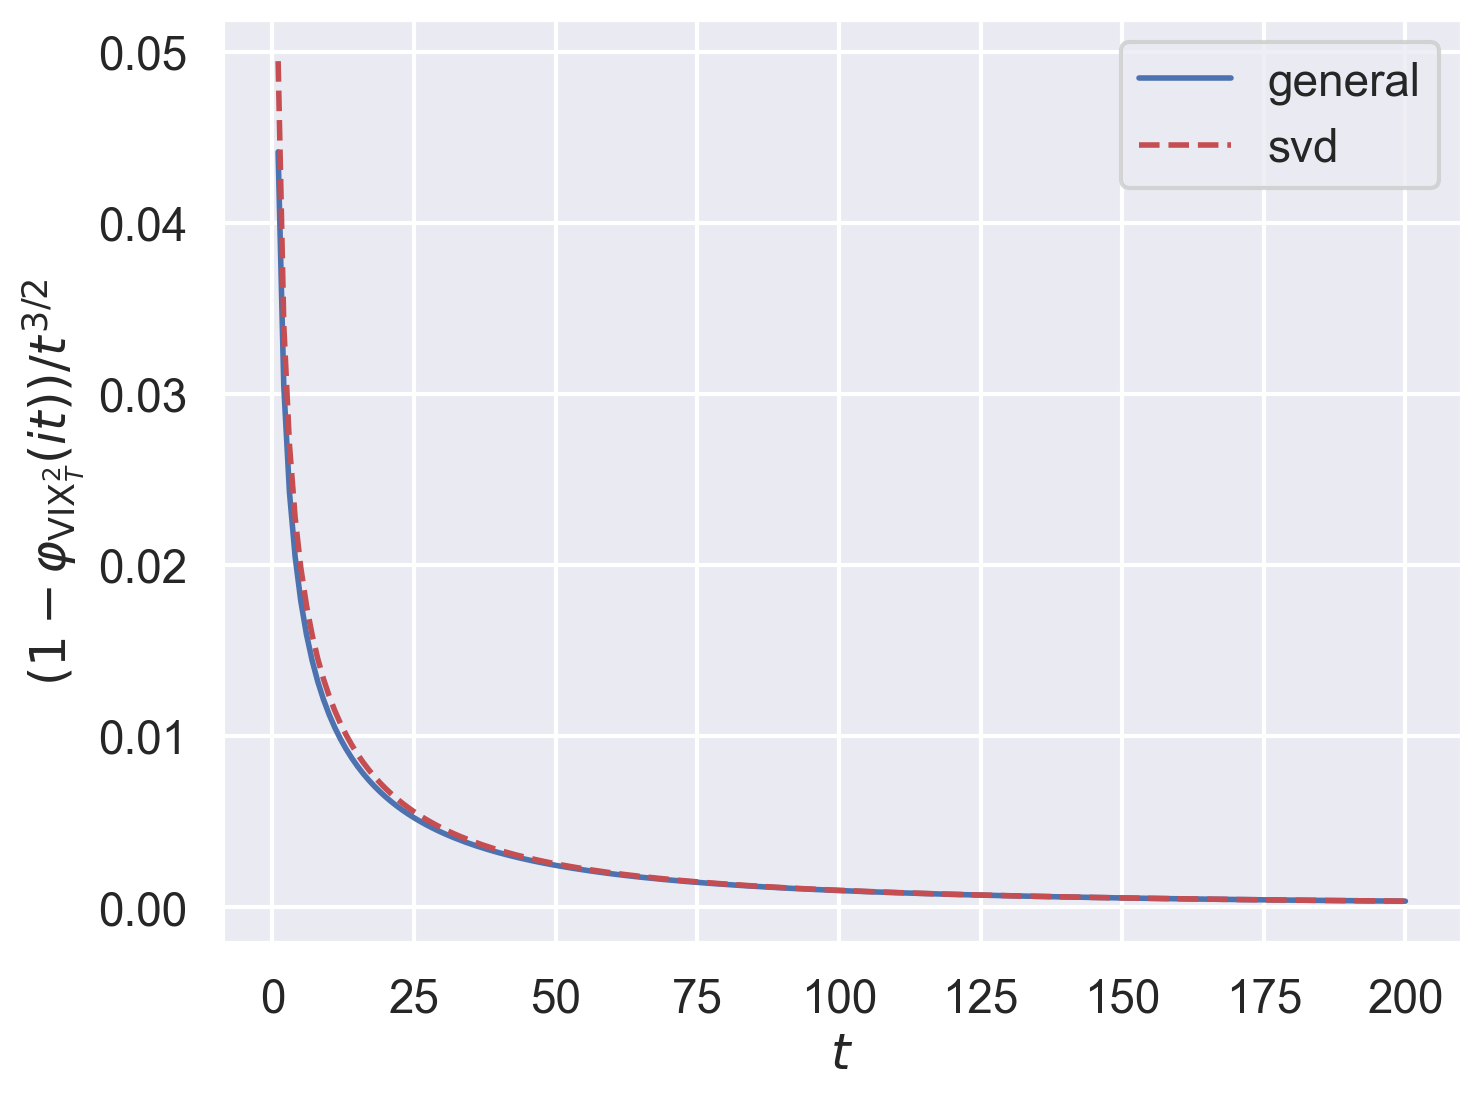

In [19]:
fig, ax = plt.subplots()
ax.plot(ts, (1 - np.real(phi_vix2_i_ts)) / ts ** (3 / 2), "b-", lw=2, label="general")
ax.plot(ts, (1 - np.real(phi_vix2_i_ts_svd)) / ts ** (3 / 2), "r--", lw=2, label="svd")
ax.set_xlabel("$t$")
ax.set_ylabel("$(1 - \\varphi_{\\mathrm{VIX}_T^2}(it)) / t^{3/2}$")
ax.legend()
plt.show()

Plot PDF of VIX

In [23]:
xs = np.linspace(np.min(vix_expiry_mc), 0.25, 101)

In [24]:
# PDF of VIX via Fourier inversion
pdf_vix_xs_svd = np.zeros_like(xs)
for i in range(len(xs)):
    # print(f"i={i}")
    pdf_vix_xs_svd[i] = utils_vix.pdf_vix(x=xs[i], a=a_scalar, b=b_vec, U=U, D=D)

/Users/florianbourgey/projects/QuadraticRoughHeston/utils_vix.py:145: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  return integrate.quad(integrand, 0.0, upper)[0] / np.pi


From a direct change of variables,
we have $f_{\mathrm{VIX}_T}(x) = 2 x \, f_{\mathrm{VIX}_T^2}(x^2)$ for all $x \geq 0$.

Gauss-Laguerre on 
$$
    f(x) = \frac{1}{\pi} \int_0^\infty \real\left( e^{-itx} \varphi(t) \right) \, dt
$$

In [30]:
# t_lag, w_lag = laggauss(180)
# cf_lag = np.array([charfunc_quadratic_normal_svd(t, a=a_scalar) for t in t_lag])
# pdf_vix_xs_lag = np.zeros_like(xs)
# for i, x in enumerate(xs):
#     pdf_vix_xs_lag[i] = (
#         np.sum(w_lag * np.real(cf_lag * np.exp(t_lag * (1.0 - 1j * x)))) / np.pi
#     )

# pdf_vix_xs_lag *= 2 * xs

Compute PDF from COS method

In [26]:
xs_cos = np.linspace(0.1, 0.5, 1001)
N = 2024
lower_cos = -5.0
upper_cos = 5.0
pdf_vix_xs_cos = utils_vix.pdf_vix_cos(
    x=xs_cos, N=N, a=a_scalar, b=b_vec, U=U, D=D, lower=lower_cos, upper=upper_cos
)

PDF plots

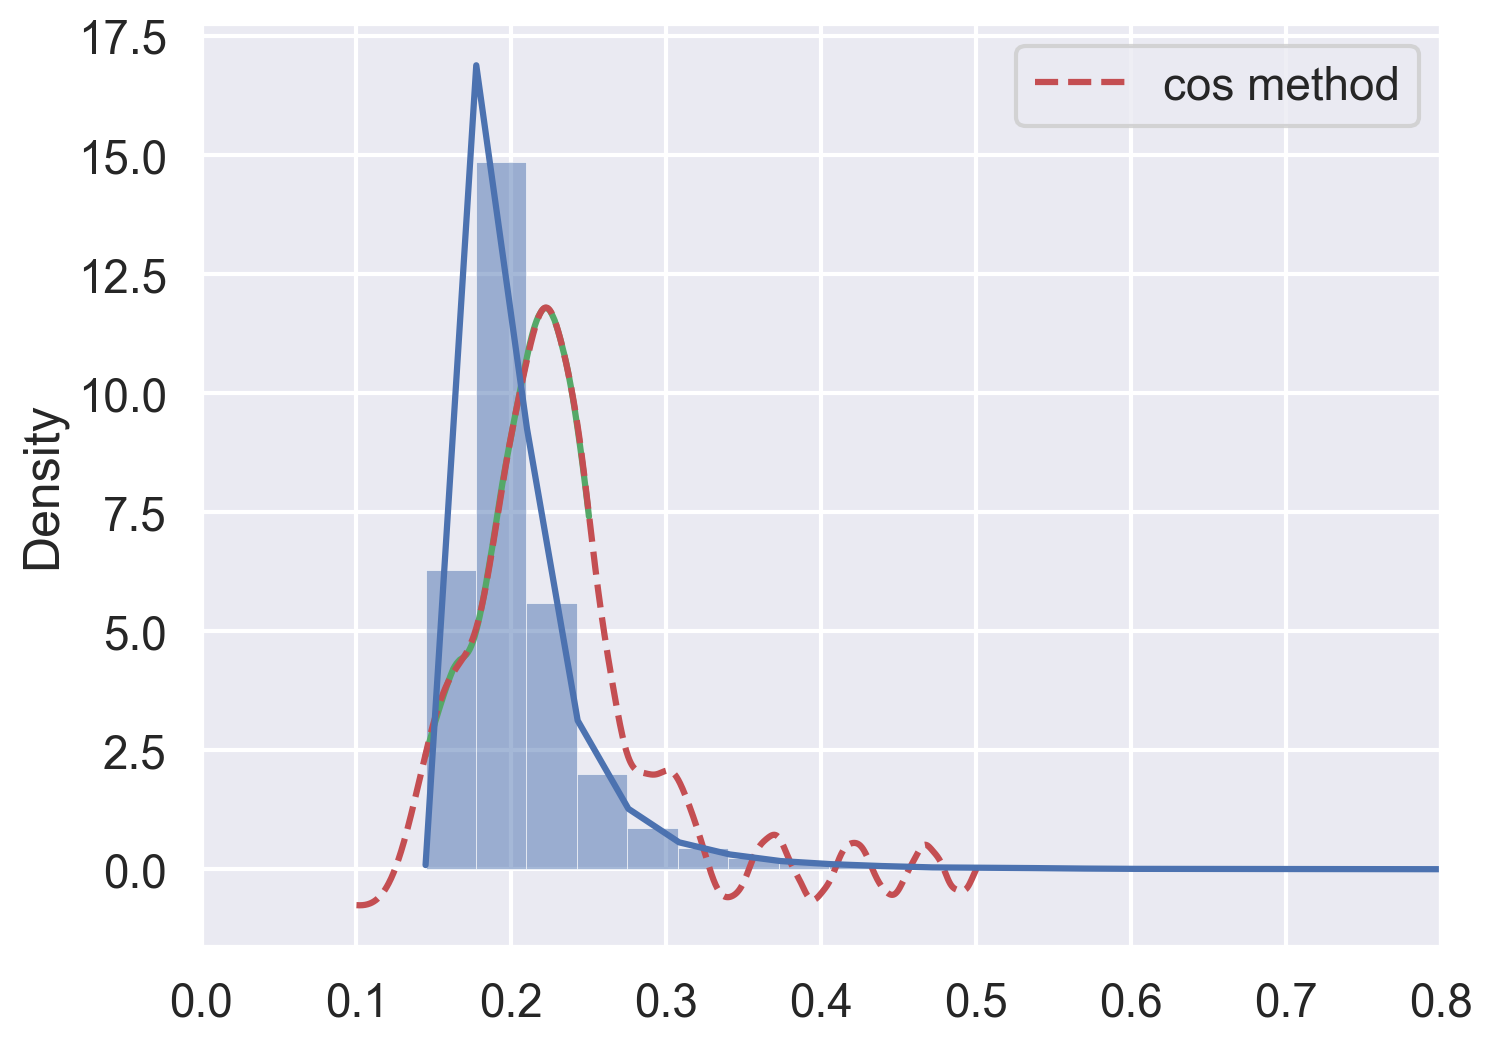

In [27]:
fig, ax = plt.subplots()
# ax.plot(xs, pdf_vix_xs_lag, ".r")
ax.plot(xs, pdf_vix_xs_svd, "-g")
ax.plot(xs_cos, pdf_vix_xs_cos, "--r", label="cos method")
sns.histplot(vix_expiry_mc, bins=200, kde=True, stat="density", ax=ax)
ax.set_xlim(0.0, 0.8)
ax.legend()
plt.show()

**Remark:** We have that

$$
\varphi_{\mathrm{VIX}_T}(t)
=
\int_0^\infty e^{-itx} f_{\mathrm{VIX}_T}(x) \, dx
=
\int_0^\infty e^{-it\sqrt{y}} f_{\mathrm{VIX}_T^2}(y) \, dy
$$

In [88]:
# trying to get implied vols from pdf with SVD PDF
# so far, we cannot use quad.integrate as the pdf is too slow,
# we use a Gauss-Legendre quadrature instead but the results are not
# very good yet

In [86]:
from utils import gauss_legendre

upper_limit = 1.0
strike = 0.2
x_leg, w_leg = gauss_legendre(strike, upper_limit, 60)

pdf_x_leg = [utils_vix.pdf_vix(x=x, a=a_scalar, b=b_vec, U=U, D=D) for x in x_leg]
pdf_x_leg = np.array(pdf_x_leg)

np.sum(w_leg * (x_leg - strike) * pdf_x_leg)

np.float64(-0.0700892148003593)

Compute VIX futures price using the representation

$$
\mathbb{E}[\text{VIX}_T] = \frac{1}{2\sqrt{\pi}}
\int_0^\infty \frac{1-\varphi_{\text{VIX}_T^2}(it)}{t^{3/2}} \, dt.
$$

In [16]:
# Monte Carlo price of vix futures
vix_fut_mc = vix_expiry_mc.mean()
error_mc = 1.95 * vix_expiry_mc.std() / np.sqrt(paths)

print(vix_fut_mc, "+/-", error_mc)

0.20710011648694418 +/- 0.00018817120095292997


In [17]:
# direct integration
# it seems that the integration is sensitive to the upper bound
def integral_vix_fut(upper=1.0e4, svd=False):
    def integrand(t):
        if svd:
            cf = utils_vix.charfunc_quadratic_normal_svd(
                1j * t, a=a_scalar, b=b_vec, U=U, D=D
            )
        else:
            cf = utils_vix.charfunc_quadratic_normal(
                1j * t, a=a_scalar, b=b_vec, C=c_mat
            )
        return np.real((1.0 - cf) / t ** (1.5))

    integral = integrate.quad(integrand, 0.0, upper)[0]
    integral /= 2.0 * np.sqrt(np.pi)
    return integral


def integral_vix_fut_change(upper=0.99, svd=False):
    "VIX futures price with change of variables."

    def integrand(z):
        if svd:
            cf = utils_vix.charfunc_quadratic_normal_svd(
                1j * (z / (1 - z)) ** 2, a=a_scalar, b=b_vec, U=U, D=D
            )
        else:
            cf = utils_vix.charfunc_quadratic_normal(
                1j * (z / (1 - z)) ** 2, a=a_scalar, b=b_vec, C=c_mat
            )
        return 2.0 * np.real((1.0 - cf) / z ** (2))

    integral = integrate.quad(integrand, 0.0, upper)[0]
    integral /= 2.0 * np.sqrt(np.pi)
    return integral

In [33]:
integral_vix_fut(upper=1e5, svd=False)

np.float64(0.20781209737159131)

In [19]:
integral_vix_fut_change(upper=0.995, svd=False)

np.float64(0.20676109795394393)

In [32]:
utils_vix.integral_vix_fut_new(a=a_scalar, b=b_vec, C=c_mat, U=U, D=D, upper=np.inf)

np.float64(0.20959622148923784)

We have another (Laplace-transform) representation 

$$
x^{3/2} = \frac{3}{4\sqrt{\pi}} \int_0^\infty (e^{-x t} -1 + x t) \, t^{-5/2} \, dt,
\qquad \forall x > 0.
$$

In [34]:
xs = np.linspace(1e-5, 10.0, 101)
p = 1.5


def integrand(t, x):
    return (3 / (4 * np.sqrt(np.pi))) * (np.exp(-x * t) - 1 + x * t) / t ** (5 / 2)


int_quad_x_32 = np.array(
    [integrate.quad(lambda t, x=x: integrand(t, x=x), 0, np.inf)[0] for x in xs]
)

/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_20850/4142407587.py:10: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  [integrate.quad(lambda t, x=x: integrand(t, x=x), 0, np.inf)[0] for x in xs]
/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_20850/4142407587.py:10: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  [integrate.quad(lambda t, x=x: 

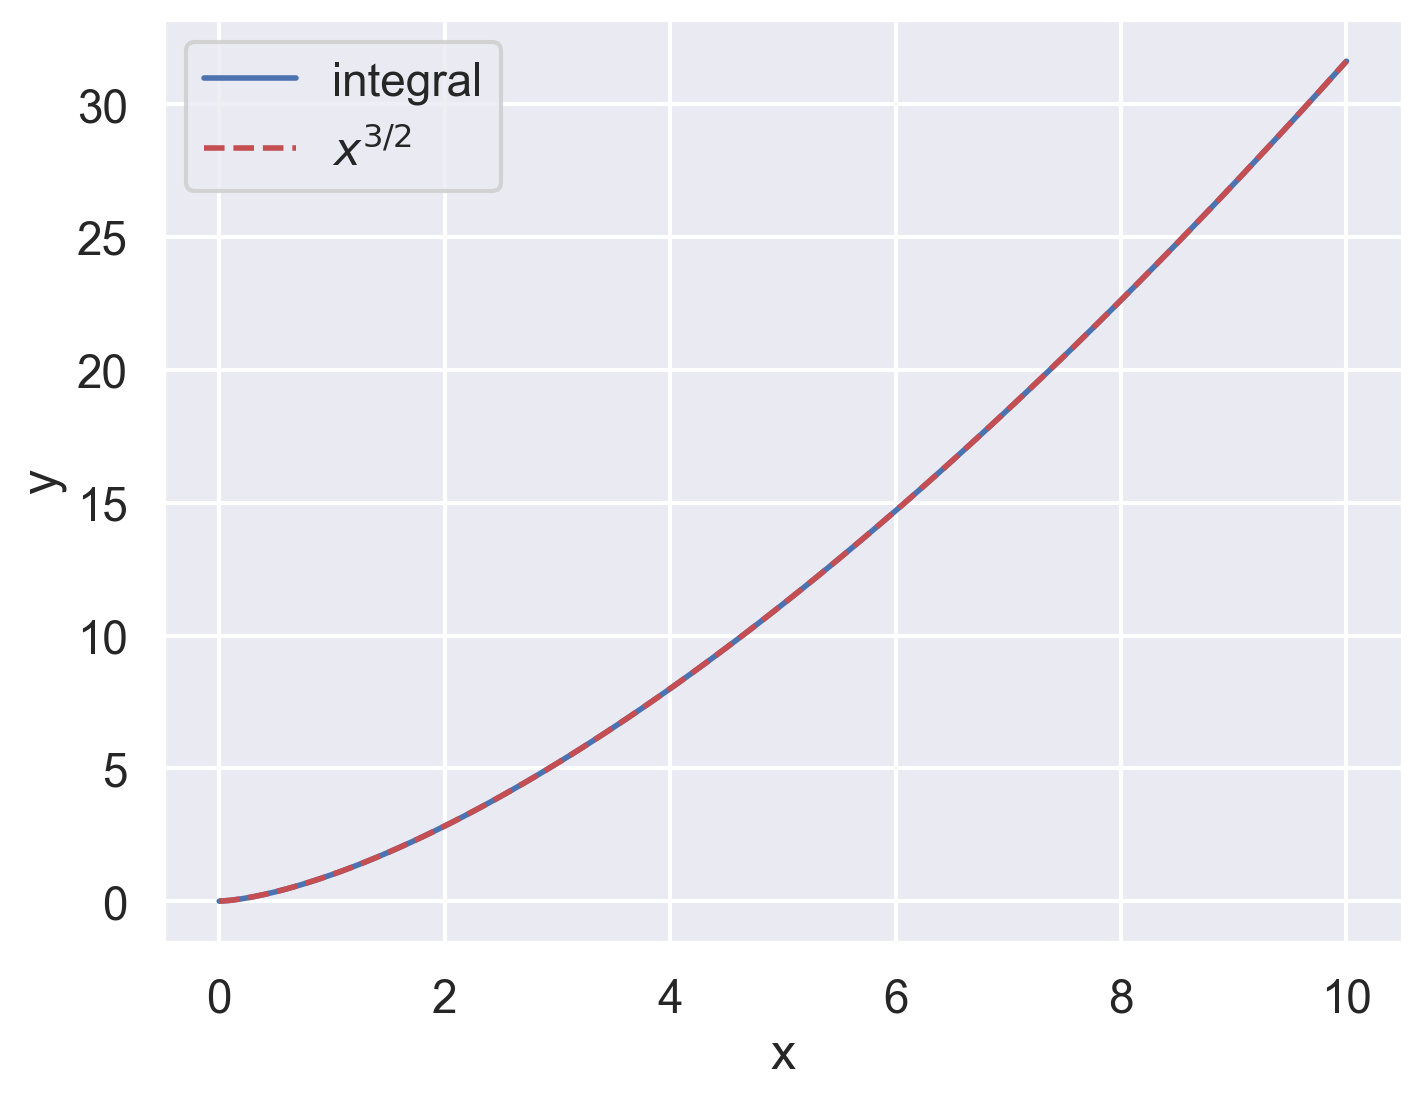

In [35]:
fig, ax = plt.subplots()
ax.plot(xs, int_quad_x_32, "b-", lw=2, label="integral")
ax.plot(xs, xs**p, "r--", lw=2, label="$x^{3/2}$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.show()

Trying with Gauss-Laguerre quadrature

$$
\mathbb{E}[\text{VIX}_T] = \frac{\sqrt{a}}{2\sqrt{\pi}}
\int_0^\infty \frac{e^{s} - f(s/a)}{s^{3/2}} e^{-s} \, ds
$$

where

$$
    f(t) = \frac{1}{\sqrt{\prod_{j=1}^{n} (1 + 2 t \lambda_j)}}
    \, \exp\left( \frac{t^2}{2} \sum_{j=1}^{n} 
    \frac{\tilde{b}_j^2}{1 + 2 t \lambda_j} \right)
$$

In [75]:
# TODO: add a method in utils_vix to compute this directly
# using Gauss-Laguerre quadrature

x_lag, w_lag = laggauss(50)


def foo(t):
    factor = np.prod(1.0 + 2 * t * D) ** (-0.5)
    return factor * np.exp(0.5 * t**2 * np.sum(U_t_b**2 / (1.0 + 2 * t * D)))


foo_lag = np.array([foo(x / a_scalar) for x in x_lag])

vix_fut_quad = (
    np.sum(w_lag * (np.exp(x_lag) - foo_lag) / x_lag ** (1.5)) * a_scalar**0.5
)
vix_fut_quad /= 2.0 * np.sqrt(np.pi)
vix_fut_quad

np.float64(-2269.716083049279)

In [37]:
vix_fut_mc

np.float64(0.20710011648694418)

We have that

$$
\begin{align*}
\mathbb{E}[\text{VIX}_{T}^{3}] 
&= 
\frac{3}{4\sqrt{\pi}}
\int_0^\infty \frac{\varphi_{\text{VIX}_T^2}(it) - 1 + \mathbb{E}[\text{VIX}_{T}^{2}]t}{t^{5/2}} \, dt 
\\
&= \frac{3a^{3/2}}{4\sqrt{\pi}}\int_0^\infty \frac{f(s/a) + (-1 + \mathbb{E}[\text{VIX}_{T}^{2}]s/a) e^{s}}{s^{5/2}} e^{-s} \, ds
\end{align*}
$$

In [70]:
# price_vix2 = integrate.quad(qrh.xi0, expiry, expiry + delta_vix)[0] / delta_vix
# price_vix2

In [79]:
# Monte Carlo price of VIX^2
price_vix2_mc = np.mean(vix_expiry_mc**2)

In [50]:
# Monte Carlo price of VIX^3
price_vix3_mc = np.mean(vix_expiry_mc**3)
print(price_vix3_mc)

0.011879893789609403


In [51]:
# get price of vix2 from cumulants
cumulants = utils_vix.cumulants_quadratic_gaussian(a_scalar, b_vec, c_mat)
price_vix2_cumulant = utils_vix.moments_from_cumulants(cumulants)[1]

In [68]:
def integral_vix_32(upper=5e5):
    def integrand(t):
        cf = utils_vix.charfunc_quadratic_normal_svd(
            1j * t, a=a_scalar, b=b_vec, U=U, D=D
        )
        return np.real((cf - 1.0 + t * price_vix2_cumulant) / t ** (2.5))

    integral = integrate.quad(integrand, 0.0, upper)[0]
    integral *= 3 / (4.0 * np.sqrt(np.pi))
    return integral

In [69]:
integral_vix_32()

/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_20850/451548011.py:8: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral = integrate.quad(integrand, 0.0, upper)[0]


np.float64(0.011859419457621513)

In [74]:
# Other method - with Gauss-Laguerre quadrature - unstable

x_lag, w_lag = laggauss(100)
foo_lag = np.array([foo(x / a_scalar) for x in x_lag])

vix_32_quad = np.sum(
    w_lag
    * (foo_lag + (-1 + price_vix2_cumulant * x_lag / a_scalar) * np.exp(x_lag))
    / x_lag ** (5 / 2)
) * a_scalar ** (3 / 2)
vix_32_quad *= 3 / (4.0 * np.sqrt(np.pi))
vix_32_quad

np.float64(2.4504335741438565e+45)

Trying to fit shifted log-normal with moments 1, 2, and 3

We want to find $\mu, \sigma, \gamma$ such that
$$
    \text{VIX}_T \stackrel{d}{=} \gamma + \exp(\mu + \sigma Z),
    \qquad Z \sim \mathcal{N}(0,1).
$$

In [172]:
# TODO: check why we are not getting the same value as a direct estimation of a shifted
# log-normal fit. # check mapping raw moments to SLN parameters.

In [108]:
m1 = integral_vix_fut(upper=1e5, svd=False)
print(m1)

0.20781209737159131


In [ ]:
m3 = integral_vix_32()

In [ ]:
print("Estimated moments:")
m2 = price_vix2_cumulant
print(f"{m1:.6f}")
print(f"{m2:.6f}")
print(f"{m3:.6f}")

Estimated moments:
0.2078
0.0453
0.0119


/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_20850/451548011.py:8: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral = integrate.quad(integrand, 0.0, upper)[0]


In [102]:
print("Monte Carlo moments:")
print(f"{vix_fut_mc:.6f}")
print(f"{price_vix2_mc:.6f}")
print(f"{price_vix3_mc:.6f}")

Monte Carlo moments:
0.207100
0.045684
0.011880


In [81]:
# fit shifted log-normal distribution
def fa1(g):
    return m1 - g


def fa2(g):
    return m2 - 2 * g * m1 + g**2


def fa3(g):
    return m3 - 3 * g * m2 + 3 * g**2 * m1 - g**3


def f_to_solve(g):
    return (m3 - 3 * g * m2 + 3 * g**2 * m1 - g**3) * (m1 - g) ** 3 - (
        m2 - 2 * g * m1 + g**2
    ) ** 3


gamma_fit = optimize.root_scalar(f_to_solve, bracket=[-0.3, 0.3]).root
sig_fit = np.sqrt(np.log(fa2(gamma_fit) / (fa1(gamma_fit) ** 2)))
mu_fit = np.log(fa1(gamma_fit)) - 0.5 * sig_fit**2

In [88]:
# var = m2 - m1**2
# third_central_moment = m3 - 3 * m1 * m2 + 2 * m1**3
# skewness = third_central_moment / var**1.5
# s = 2 * np.sinh(np.asinh(skewness / 2) / 3)
# w = s**2 + 1
# sig = np.sqrt(np.log(w))
# mu = 0.5 * np.log(var / (w * (w - 1)))
# gamma = m1 - np.sqrt(var / s**2)

In [82]:
# sanity check
# we check that all raw moments match
exp_sln = np.exp(mu_fit + sig_fit**2 / 2)
exp2_sln = np.exp(2 * mu_fit + 2 * sig_fit**2)
exp3_sln = np.exp(3 * mu_fit + 9 * sig_fit**2 / 2)

m1_sln = gamma_fit + exp_sln
m2_sln = gamma_fit**2 + 2 * gamma_fit * exp_sln + exp2_sln
m3_sln = gamma_fit**3 + 3 * gamma_fit**2 * exp_sln + 3 * gamma_fit * exp2_sln + exp3_sln

assert np.allclose(m1, m1_sln)
assert np.allclose(m2, m2_sln)
assert np.allclose(m3, m3_sln)

In [83]:
# print parameters of the shifted log-normal fit
print(mu_fit, sig_fit, gamma_fit)

-4.719736670141328 1.3161840917937289 0.1866081175692252


In [84]:
# # from estimation after

# mu_fit = np.log(0.0336)
# sig_fit = 0.5325
# gamma_fit = 0.1470

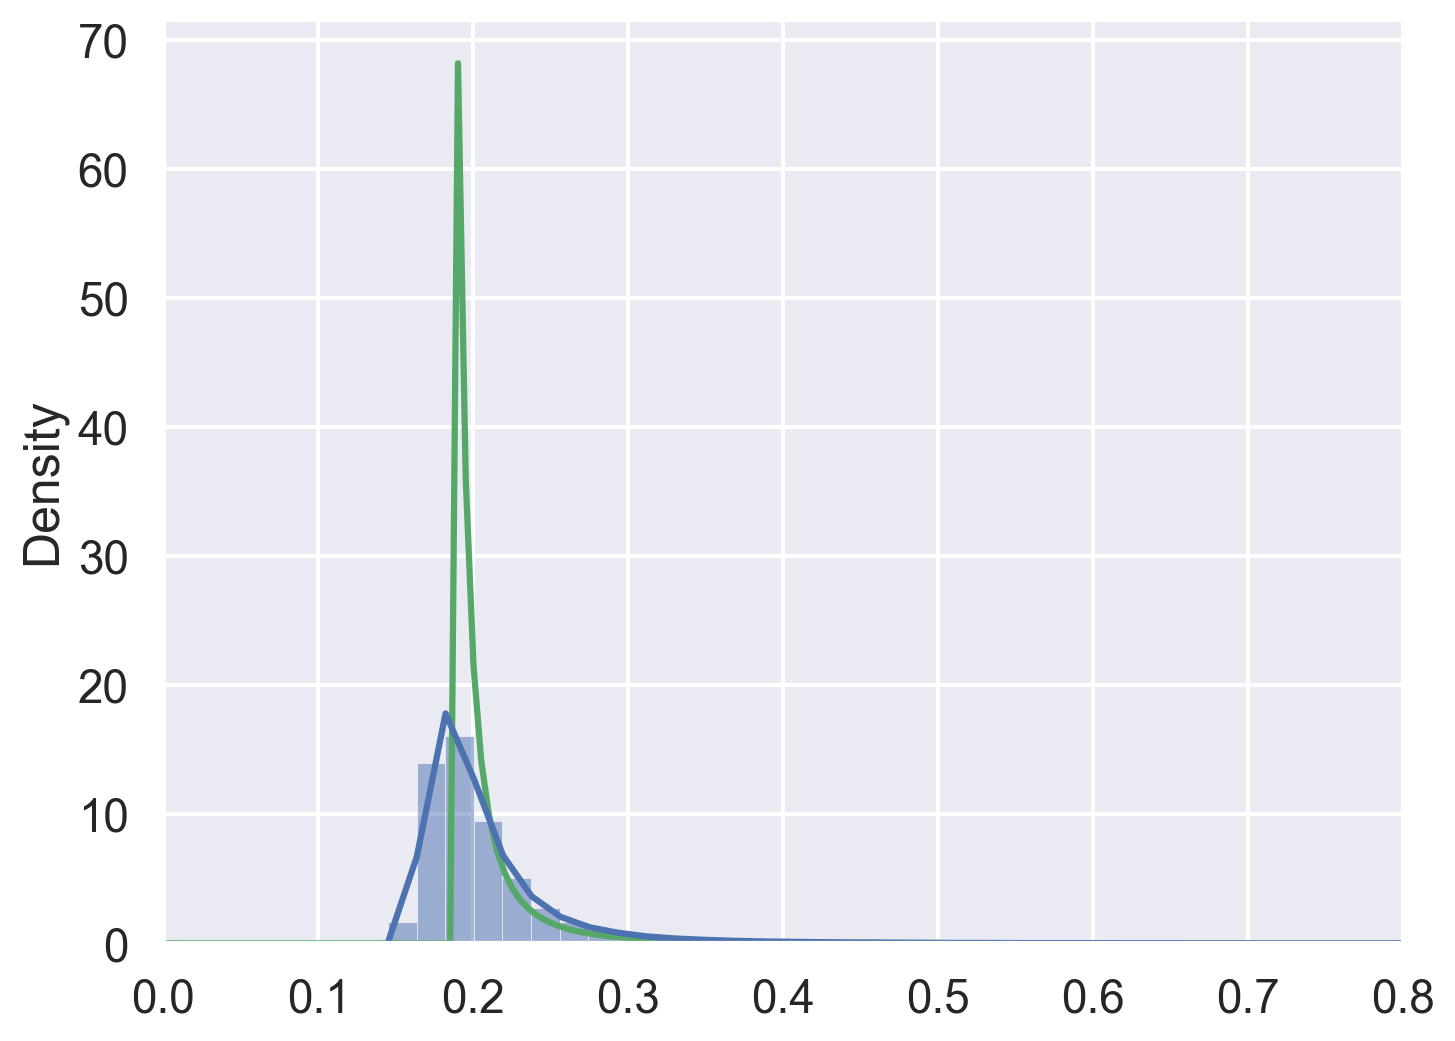

In [85]:
xs = np.linspace(1e-5, 0.5, 101)

fig, ax = plt.subplots()
ax.plot(xs, stats.lognorm.pdf(xs, s=sig_fit, scale=np.exp(mu_fit), loc=gamma_fit), "-g")
sns.histplot(vix_expiry_mc, bins=200, kde=True, stat="density", ax=ax)
ax.set_xlim(0.0, 0.8)
plt.show()

In [88]:
from black import black_impvol_brentq, black_otm_impvol_mc

In [89]:
# # TODO: code shifted lognormal implied vol and see if we get the same smile.
# vol = sig_fit / np.sqrt(expiry)  # convert to annualized vol
# F = np.exp(mu_fit + 0.5 * vol**2 * expiry)
# ks = np.linspace(-0.1, 0.6, 11)
# # Ks = np.exp(ks) * F + gamma_fit
# Ks = np.linspace(0.0, 0.8, 11)

# for i in range(len(Ks)):
#     K_shift_i = Ks[i] - gamma_fit
#     if K_shift_i <= 0:
#         black_price_shifted = F - Ks[i]
#     else:
#         black_price_shifted = black_price(K=K_shift_i, T=expiry, F=F, vol=vol)
#     # print(black_price_shifted)
#     print(black_impvol_brentq(K_shift_i, expiry, F, black_price_shifted))

In [90]:
def pdf_shifted_lognormal(x, mu, sigma, delta):
    x = np.asarray(np.atleast_1d(x))
    pdf = np.zeros_like(x)
    mask = x > delta
    x_scaled = (np.log(x[mask] - delta) - mu) / sigma
    pdf[mask] = np.exp(-0.5 * x_scaled**2) / (
        (x[mask] - delta) * sigma * np.sqrt(2 * np.pi)
    )
    return pdf

In [98]:
ks = np.linspace(-0.2, 1.4, 21)
F = integrate.quad(
    lambda s: s * pdf_shifted_lognormal(s, mu_fit, sig_fit, gamma_fit),
    gamma_fit,
    np.inf,
)[0]
Ks = F * np.exp(ks)
price_otm_sln = np.zeros_like(Ks)

for i, K in enumerate(Ks):
    if K <= F:
        price_otm_sln[i] = integrate.quad(
            lambda s, K=K: (K - s)
            * pdf_shifted_lognormal(s, mu_fit, sig_fit, gamma_fit),
            gamma_fit,
            K,
        )[0]
    else:
        price_otm_sln[i] = integrate.quad(
            lambda s, K=K: (s - K)
            * pdf_shifted_lognormal(s, mu_fit, sig_fit, gamma_fit),
            K,
            np.inf,
        )[0]

vix_impvol_sln = black_impvol_brentq(
    K=Ks, T=expiry, F=F, value=price_otm_sln, opttype=2 * (np.array(Ks) > F) - 1
)

In [99]:
vix_impvol_mc = black_otm_impvol_mc(S=vix_expiry_mc, k=ks, T=expiry)

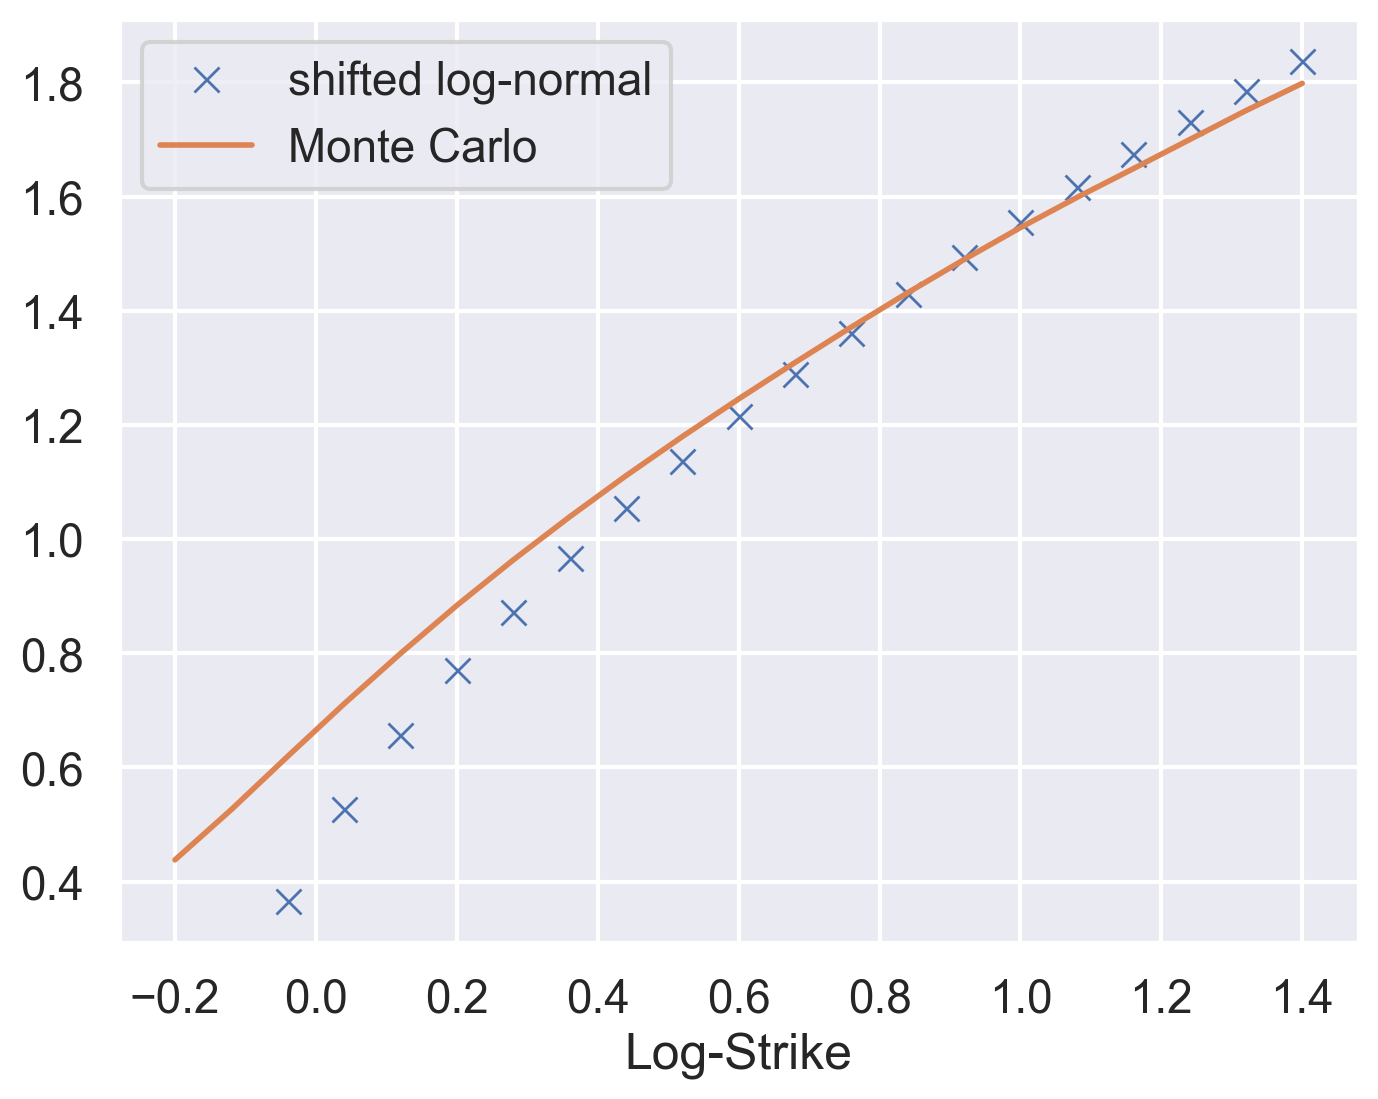

In [109]:
fig, ax = plt.subplots()
ax.plot(ks, vix_impvol_sln, "x", lw=2, label="shifted log-normal")
ax.plot(ks, vix_impvol_mc, "-", lw=2, label="Monte Carlo")
ax.legend()
ax.set_xlabel("Log-Strike")
plt.show()

Plot all VIX smiles

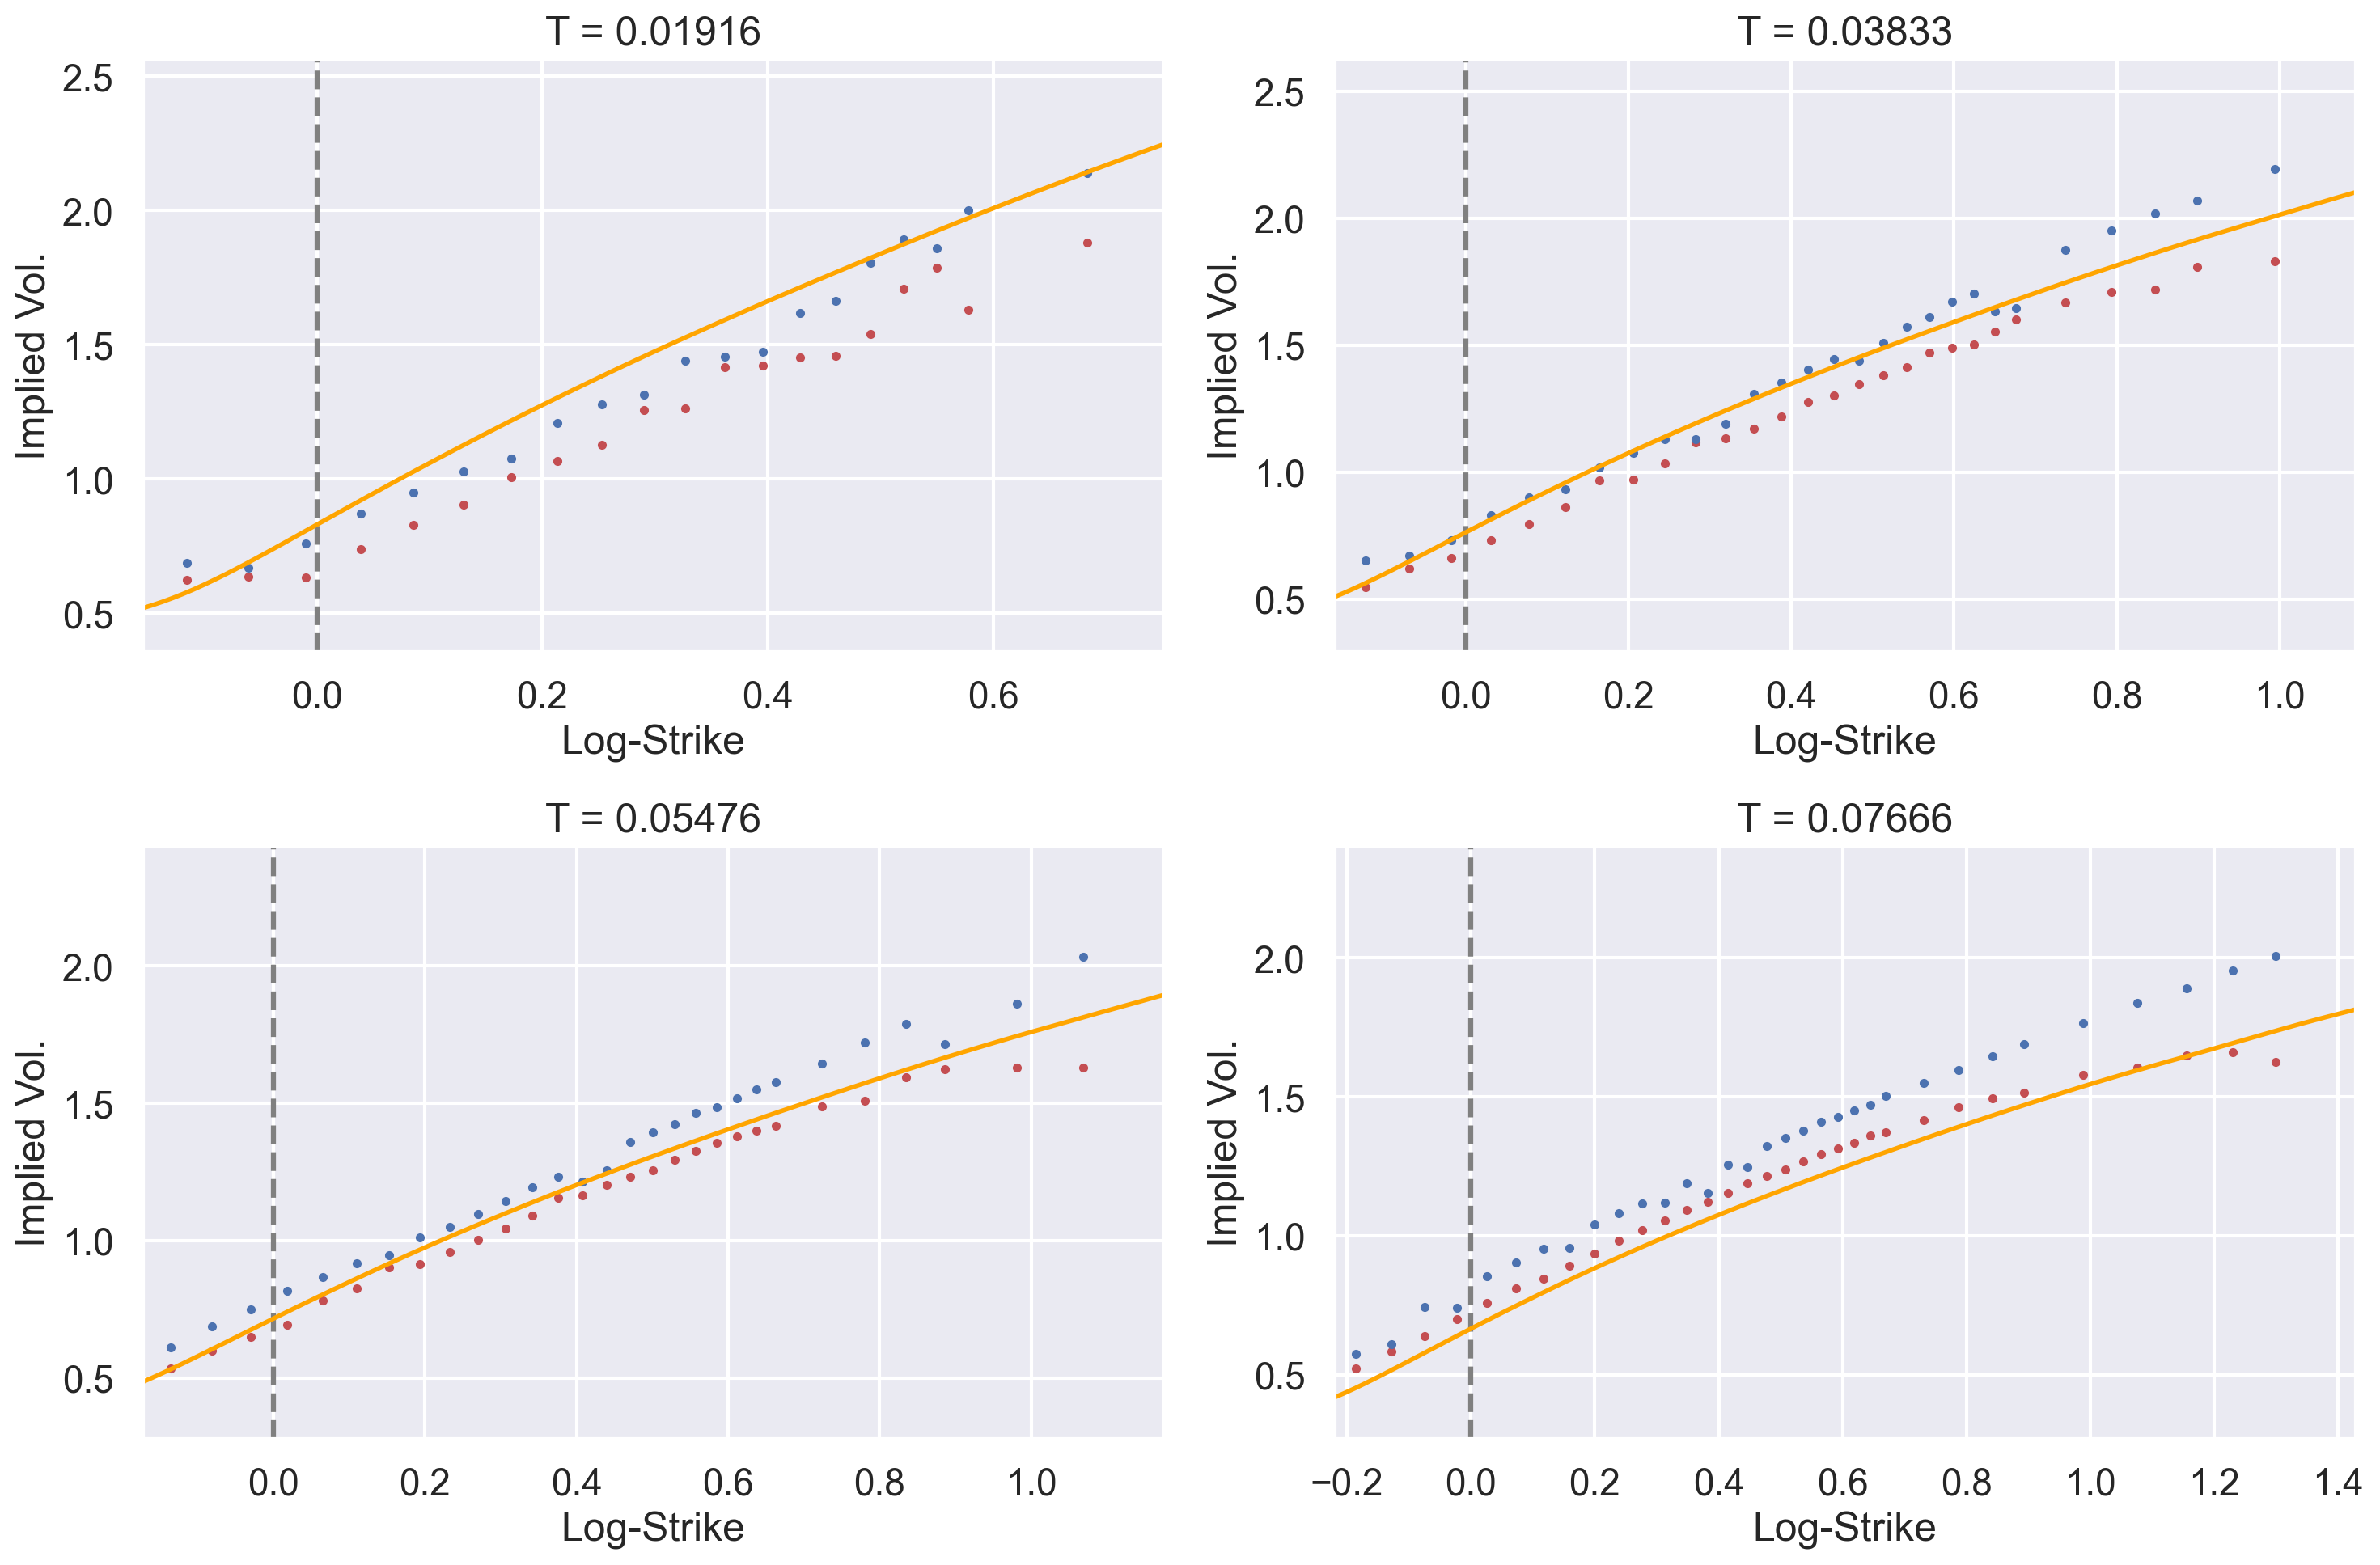

In [97]:
from utils import plot_ivols_mc

vix_mc_matrix = np.array([qrh_sim[exp]["vix"] for exp in vix_expiries])
df_vix_sub = (
    df_vix[df_vix["Texp_days"].isin(vix_expiries_days)].dropna().reset_index(drop=True)
)
plot_vix = plot_ivols_mc(ivol_data=df_vix_sub, mc_matrix=vix_mc_matrix)

### Trying to fit a shifted lognormal

Let $X \sim \exp\big\{ \mathcal{N}(\mu,\sigma^2) \big\} + \delta$ where $\delta \in \mathbb{R}$ is a shift parameter. The PDF of $X$ is 

$$
    f_{X}(x;\mu,\sigma,\delta)
    =
    \frac{1}{(x - \delta) \sigma \sqrt{2\pi}} \exp\left(-\frac{(\ln(x - \delta) - \mu)^2}{2\sigma^2}\right),
    \qquad
    \forall x \geq \delta.
$$

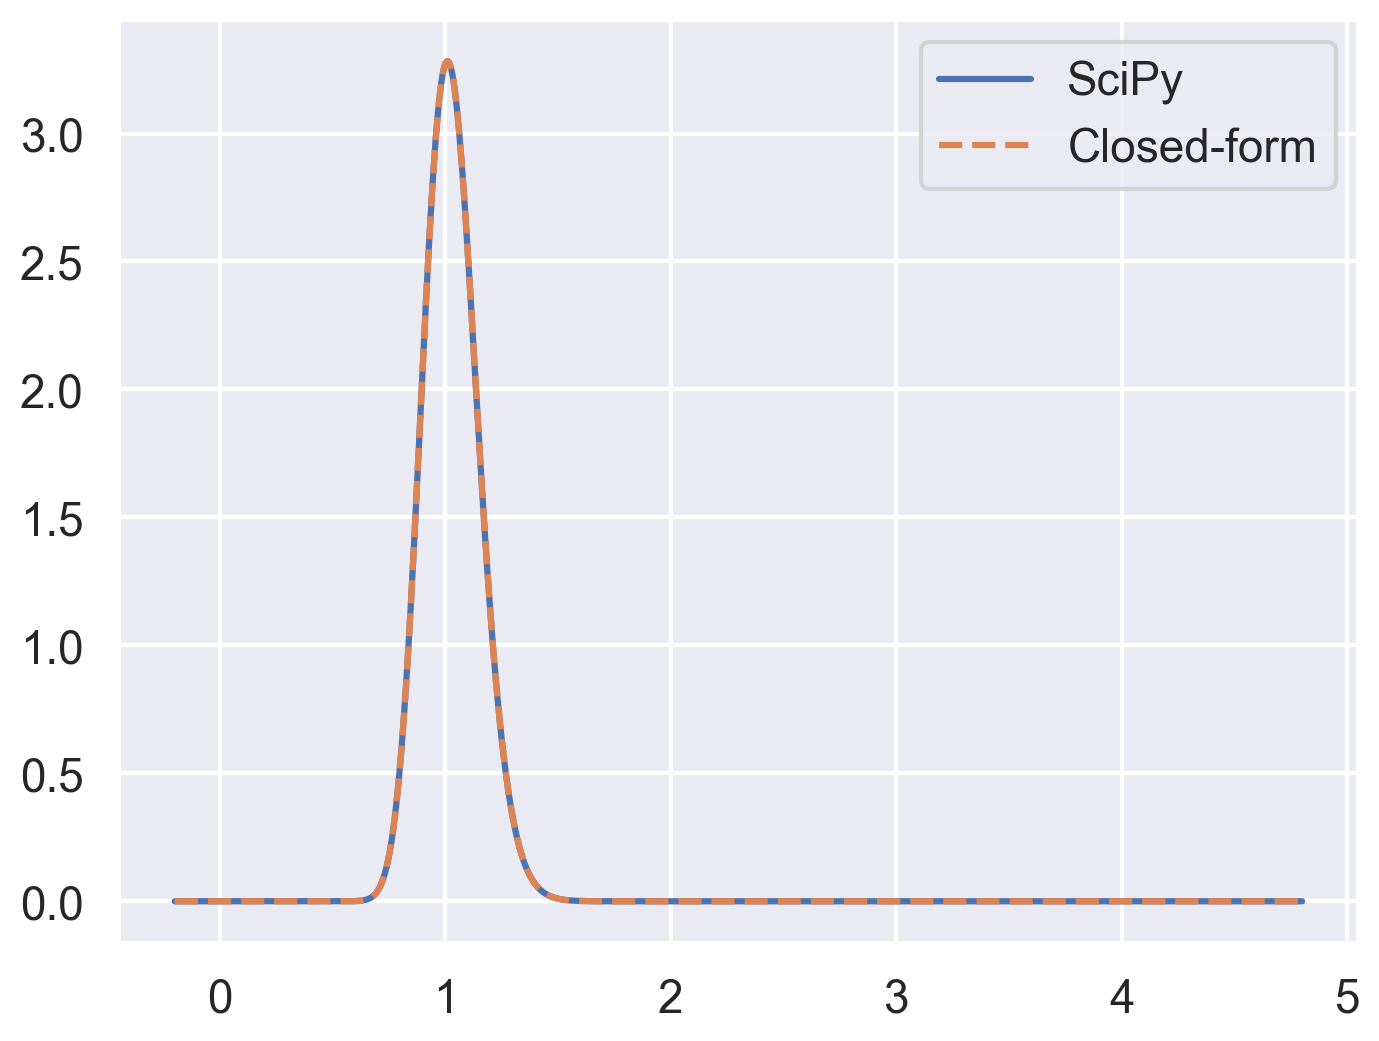

In [146]:
# Check PDF formula


def f_pdf(x, mu, sigma, delta):
    x = np.asarray(np.atleast_1d(x))
    pdf = np.zeros_like(x)
    mask = x > delta
    x_scaled = (np.log(x[mask] - delta) - mu) / sigma
    pdf[mask] = np.exp(-0.5 * x_scaled**2) / (
        (x[mask] - delta) * sigma * np.sqrt(2 * np.pi)
    )
    return pdf


mu = 0.2
sigma = 1e-1
shift = -0.2
xs = np.linspace(shift, shift + 5.0, 1000)
stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift)

fig, ax = plt.subplots()
ax.plot(
    xs,
    stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift),
    label="SciPy",
)
ax.plot(xs, f_pdf(xs, mu, sigma, shift), label="Closed-form", linestyle="--")
ax.legend()
plt.show()

In [147]:
# Sanity check: example on simulated data

true_mean, true_sigma, true_shift = 1.0, 0.5, 2.0
size = 10**5
data = np.exp(true_mean + true_sigma * np.random.randn(size)) + true_shift

# Fit shifted log normal
sigma, shift, scale = stats.lognorm.fit(data)

In [148]:
print("Fitted parameters:")
print(f"  Shape (sigma): {sigma:<.4f}  | {true_sigma:<.4f} (true)")
print(f"  Location (shift): {shift:<.4f}  | {true_shift:<.4f} (true)")
print(f"  Scale (scale): {scale:<.4f}  | {np.exp(true_mean):<.4f} (true)")

Fitted parameters:
  Shape (sigma): 0.5055  | 0.5000 (true)
  Location (shift): 2.0206  | 2.0000 (true)
  Scale (scale): 2.6893  | 2.7183 (true)


In [110]:
# grid for plotting
x_grid = np.linspace(min(data), max(data), 301)
# fitted pdf
pdf_vals = stats.lognorm.pdf(x_grid, s=sigma, scale=scale, loc=shift)

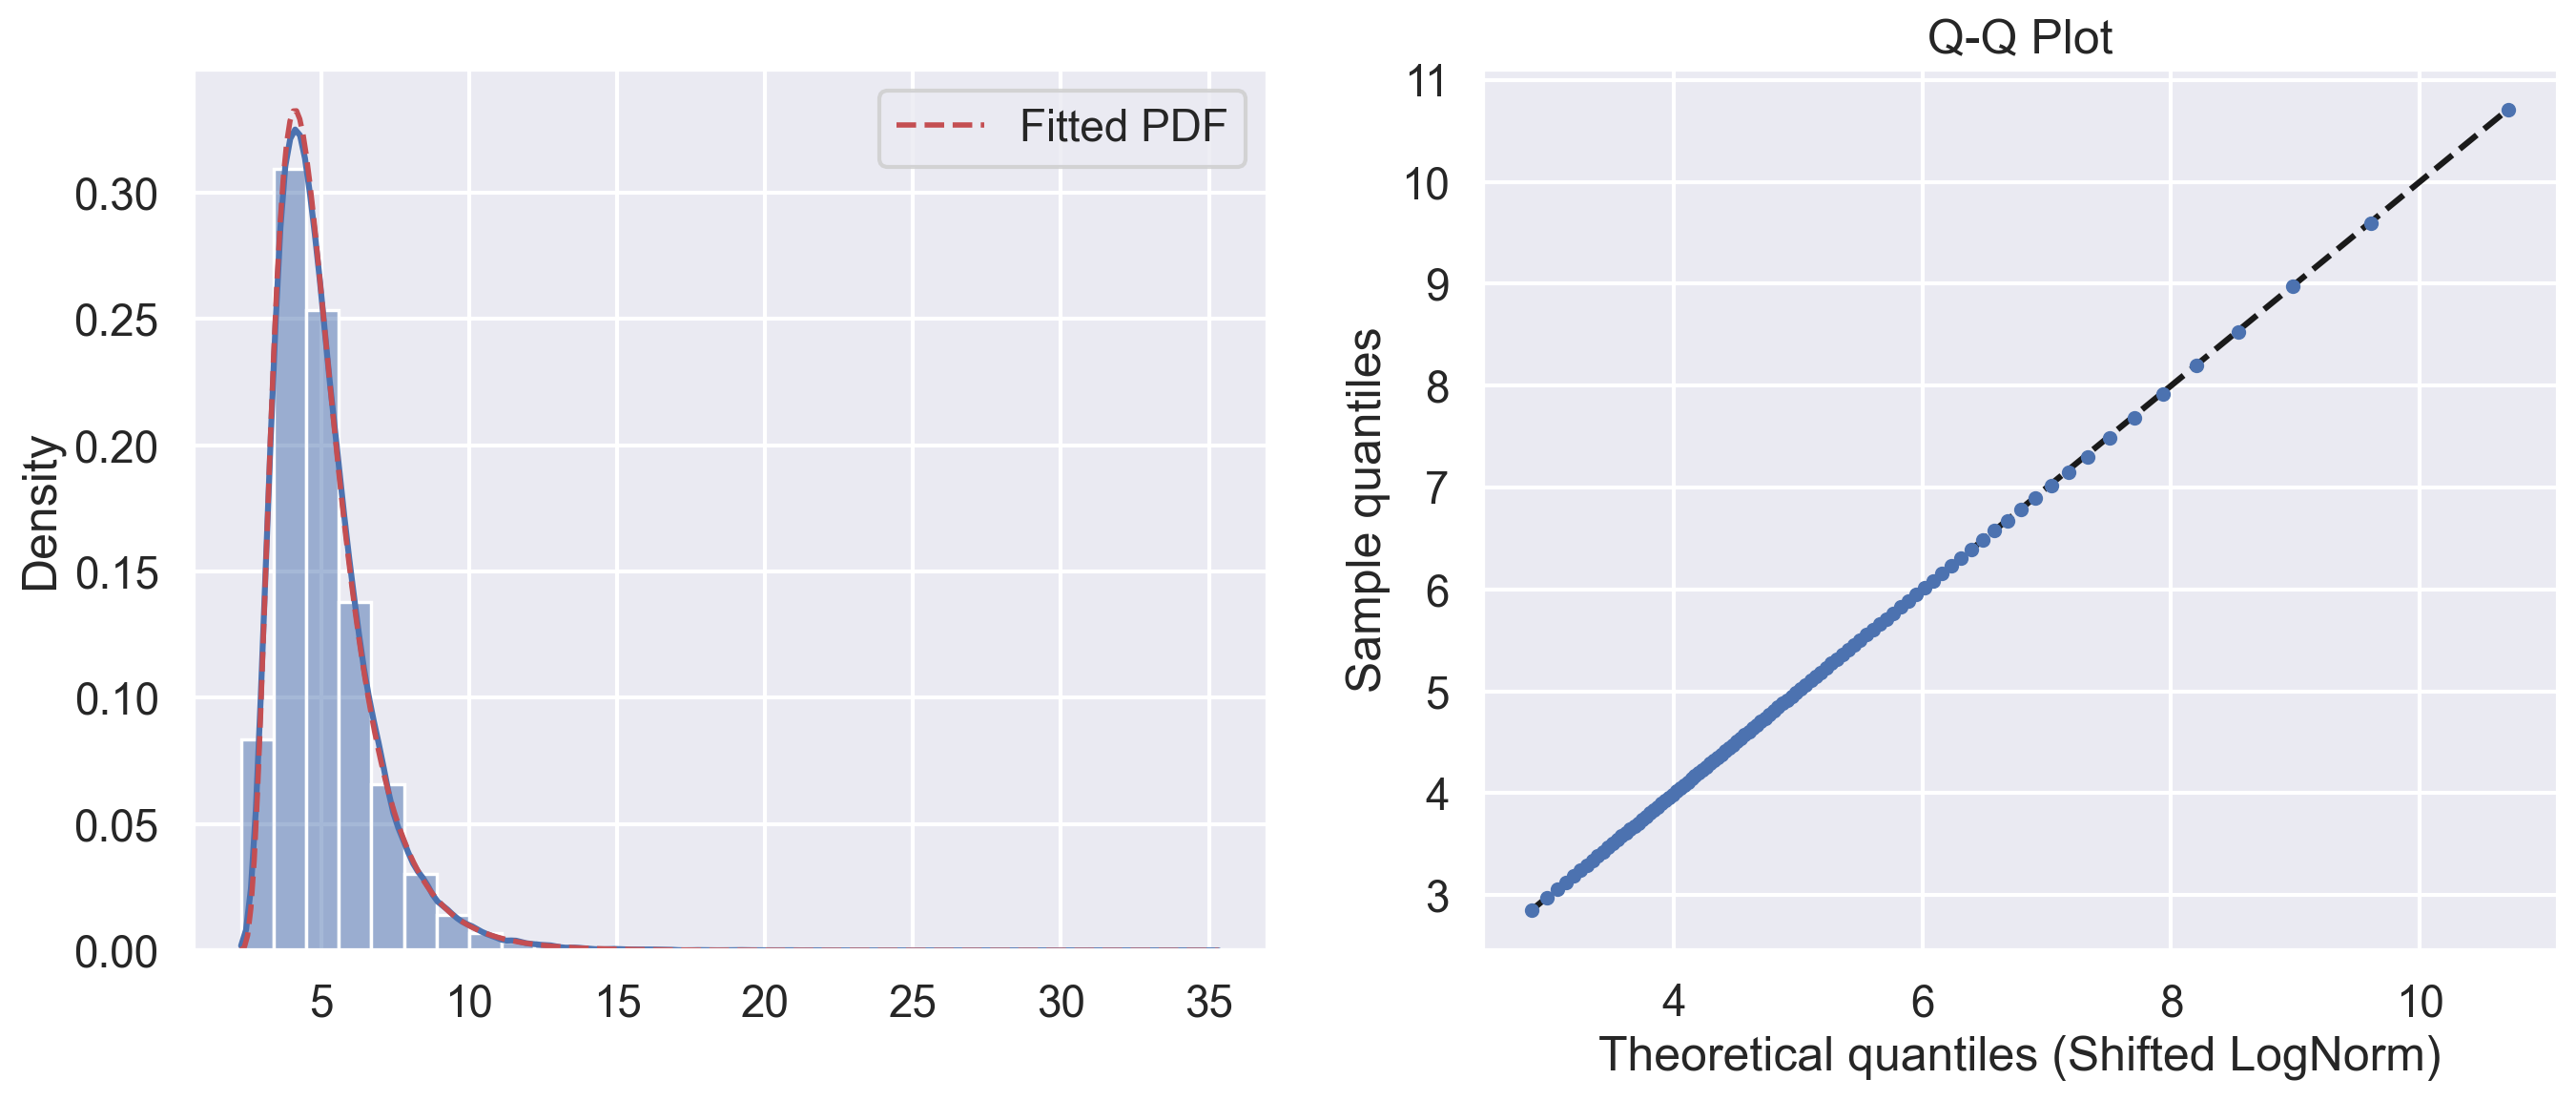

In [111]:
fig, ax = plt.subplots(1, 2, figsize=(2 * 8, 6))
sns.histplot(data, bins=30, kde=True, ax=ax[0], stat="density")
ax[0].plot(x_grid, pdf_vals, "r--", lw=2, label="Fitted PDF")
ax[0].legend()

quantiles = np.linspace(1e-2, 1 - 1e-2, 100)
lognorm_ppf = stats.lognorm.ppf(quantiles, s=sigma, scale=scale, loc=shift)

# Q-Q plot
ax[1].plot(lognorm_ppf, lognorm_ppf, "k--")
ax[1].plot(lognorm_ppf, np.quantile(data, quantiles), ".")
ax[1].set_xlabel("Theoretical quantiles (Shifted LogNorm)")
ax[1].set_ylabel("Sample quantiles")
ax[1].set_title("Q-Q Plot")

plt.show()

Now, do the same for the VIX

In [112]:
fitted_params = {}

for T_i in spx_expiries:
    vix_Ti = qrh_sim[T_i]["vix"]
    s, loc, scale = stats.lognorm.fit(vix_Ti)
    fitted_params[T_i] = {"shape": s, "location": loc, "scale": scale}

    print(f"Fitted parameters: (T={T_i:<.4f})")
    print(f"  Shape (sigma): {s:<.4f}")
    print(f"  Location (shift): {loc:<.4f}")
    print(f"  Scale (scale): {scale:<.4f}")

Fitted parameters: (T=0.0192)
  Shape (sigma): 0.5325
  Location (shift): 0.1470
  Scale (scale): 0.0336
Fitted parameters: (T=0.0383)
  Shape (sigma): 0.5748
  Location (shift): 0.1454
  Scale (scale): 0.0410
Fitted parameters: (T=0.0548)
  Shape (sigma): 0.5807
  Location (shift): 0.1445
  Scale (scale): 0.0465
Fitted parameters: (T=0.0767)
  Shape (sigma): 0.5874
  Location (shift): 0.1445
  Scale (scale): 0.0516


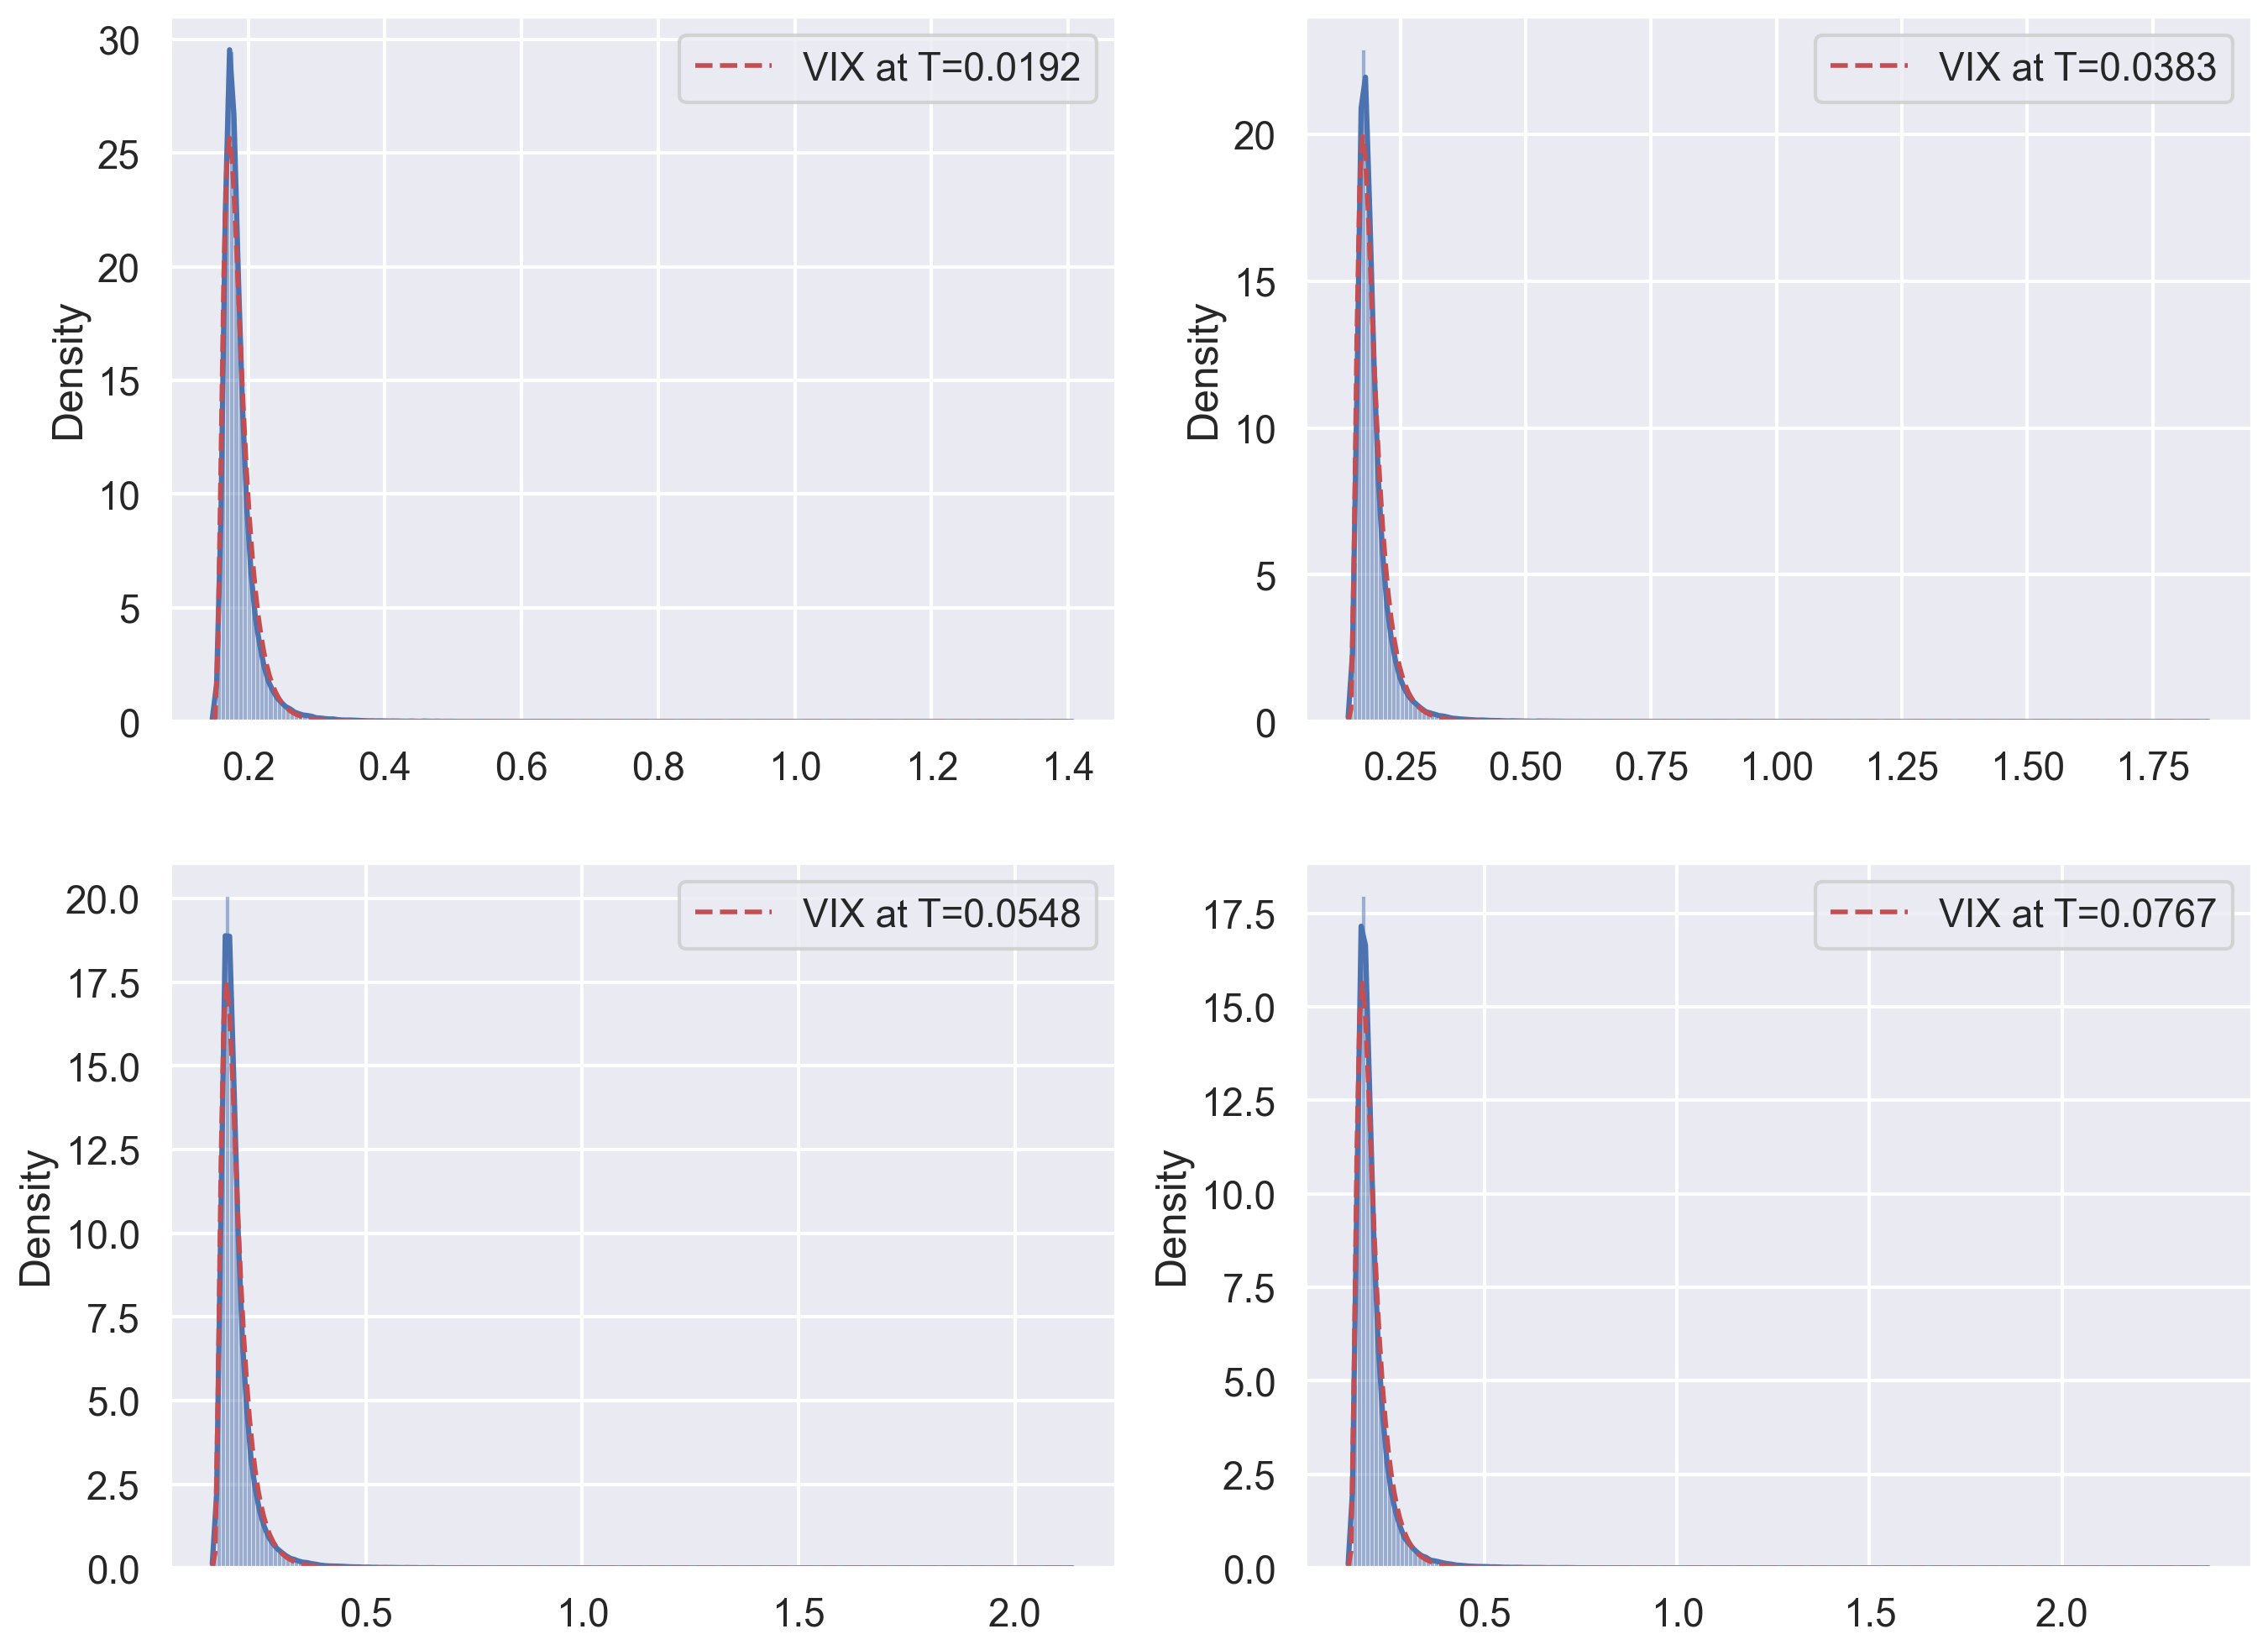

In [113]:
fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    x_grid_vix = np.linspace(np.min(vix_Ti), np.max(vix_Ti), 301)
    sns.histplot(vix_Ti, bins=200, ax=ax_i, kde=True, stat="density")
    ax_i.plot(
        x_grid_vix,
        stats.lognorm.pdf(x_grid_vix, shape_i, loc_i, scale_i),
        "r--",
        lw=2,
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.legend()
plt.show()

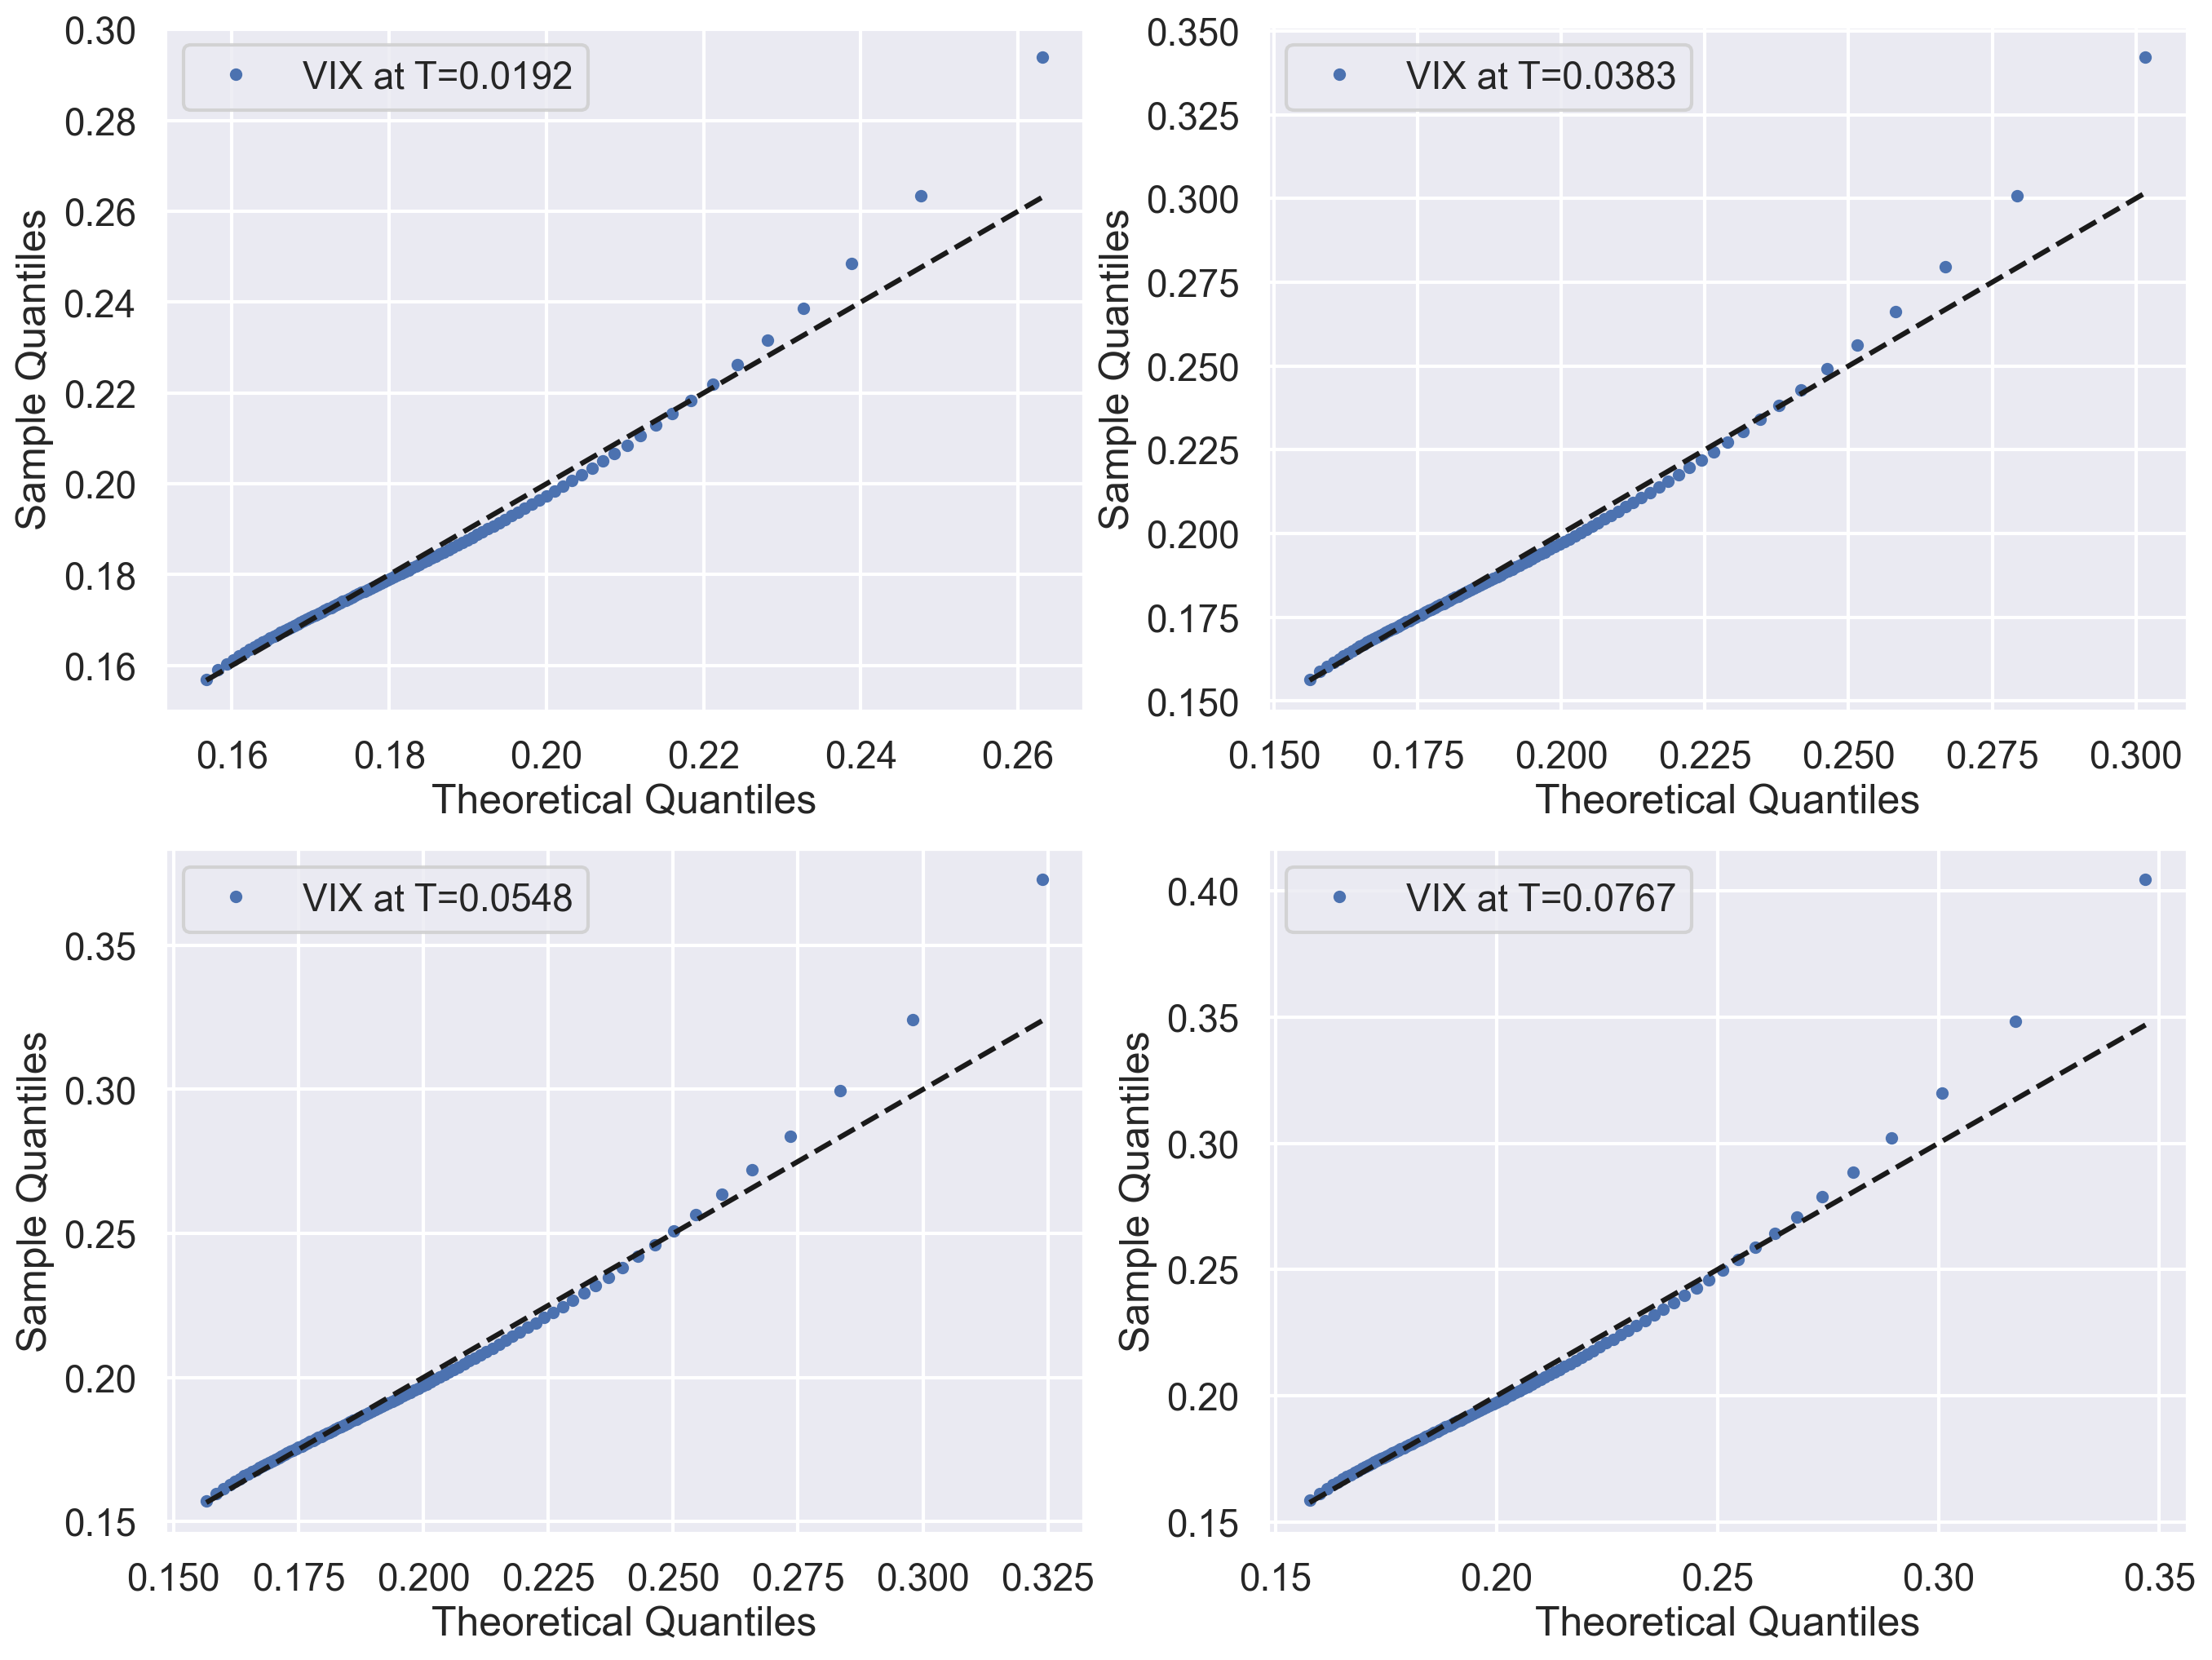

In [114]:
# Q-Q plot

quantiles = np.linspace(1e-2, 1 - 1e-2, 101)

fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    # plot
    lognorm_ppf = stats.lognorm.ppf(quantiles, shape_i, loc_i, scale_i)
    ax_i.plot(
        lognorm_ppf,
        np.quantile(vix_Ti, q=quantiles),
        ".",
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.plot(lognorm_ppf, lognorm_ppf, "k--")
    ax_i.legend()
    ax_i.set_xlabel("Theoretical Quantiles")
    ax_i.set_ylabel("Sample Quantiles")
plt.show()

### Approximation of the VIX

In the QRH model, we made the approximation
$$
    \mathrm{VIX}_T^2
    =
    \frac{1}{\delta} 
    \int_0^\delta
    \big[    
        \bigl(y_0(T+u) + \sum_{k=1}^{n} a_k(T+u) \chi_k\bigr)^2 + c
    \big] w(u) du
$$

where:

- $w(u) = 1 + K_0(\delta-u)$

- $\chi_k = \int_{(k-1)\Delta}^{k\Delta} \sqrt{V_s} \, dW_s, \qquad 1 \leq k \leq n$

- $\Delta = T/n$ and $\delta = 30/365$.

We have that

$$
    \mathrm{VIX}_T^2
    =
    a_0(T) 
    + 
    \sum_{i=1}^{n} b_i(T) \chi_i 
    + 
    \sum_{i,j=1}^{n} c_{ij}(T) \chi_i \chi_j,
$$

where:

$$
    a_0(T) = \frac{1}{\delta} \int_0^\delta \big[ y_0(T+u)^2 + c \big] w(u) du,
$$

$$
    b_i(T) = \frac{2}{\delta} \int_0^\delta y_0(T+u) a_i(T+u) w(u) du,
$$

$$
    c_{ij}(T) = \frac{1}{\delta} \int_0^\delta a_i(T+u) a_j(T+u) w(u) du.
$$

We have also that

$$
    \mathbb{E}[\chi_k] = 0,
    \qquad
    \mathbb{E}[\chi_k^2] 
    = \int_{(k-1)\Delta}^{k\Delta} \xi_0(s) \, ds = \Delta \overline{\xi}_k,
$$

In [82]:
# test_0
np.random.seed(SEED)
n_paths = 1 * 10**6

a = 1.5
b = np.array([-1.0, 1.0])
C = np.array(
    [
        [1.0, 0.5],
        [0.5, 1.0],
    ]
)


Z = np.random.randn(b.shape[0], n_paths)

$S_n = a + b^\top Z + Z^\top C Z$ where $Z \sim \mathcal{N}(0, I)$ and $C$ is a symmetric matrix.

In [83]:
S_n = a + b @ Z + np.sum(Z * (C @ Z), axis=0)

In [84]:
# mean
mean_S_n = a + np.trace(C)

print(np.mean(S_n))
print(mean_S_n)

3.5019043520878026
3.5


In [85]:
# variance
variance_S_n = b.T @ b + 2 * np.trace(C @ C)

print(np.var(S_n))
print(variance_S_n)

7.014640381126598
7.0


In [86]:
# third cumulant = third central moment
third_cumulant_S_n = 6 * b.T @ C @ b + 8 * np.trace(C @ C @ C)

print(np.mean((S_n - np.mean(S_n)) ** 3))
print(third_cumulant_S_n)

33.962994823509646
34.0


In [92]:
# fourth_cumulant

fourth_cumulant_S_n = 48 * b.T @ C @ C @ b + 48 * np.trace(C @ C @ C @ C)

print(np.mean((S_n - np.mean(S_n)) ** 4) - 3 * np.var(S_n) ** 2)
print(fourth_cumulant_S_n)

266.2350318980734
270.0


Define $s_n = \sqrt{S_n}$

In [87]:
s_n = np.sqrt(S_n)

In [89]:
# approx mean s_n
print(np.mean(s_n))


approx_mean_s_n = (
    np.sqrt(mean_S_n)
    - variance_S_n / (8 * (mean_S_n) ** 1.5)
    + third_cumulant_S_n / (16 * (mean_S_n) ** 2.5)
)
print(approx_mean_s_n)

# it does not seem to work...

1.7558831612262396
1.8299213604411915


Can we use a Variance Gamma approx?

In [ ]:
from scipy import optimize

r = third_cumulant_S_n**2 / (variance_S_n * fourth_cumulant_S_n)


def func(u):
    return 3 * r * u**3 + (12 * r - 9) * u**2 + (18 * r - 12) * u + (6 * r - 4)


result = optimize.root_scalar(func, bracket=[-10, 10])

In [102]:
u = result.root

In [107]:
A = (third_cumulant_S_n**2 * (1 + u) ** 2) / (variance_S_n**2 * (2 + 3 * u) ** 2)
theta = np.sign(third_cumulant_S_n) * np.sqrt(A)
sig2 = u * A
k = variance_S_n / (theta**2 + sig2)
mu = mean_S_n - k * theta

In [109]:
print(mean_S_n)
print(mu + k * theta)

3.5
3.5


In [110]:
print(variance_S_n)
print(k * (theta**2 + sig2))

7.0
7.0


In [111]:
print(third_cumulant_S_n)
print(k * theta * (3 * sig2 + 2 * theta**2))

34.0
33.99999999999999


In [113]:
print(fourth_cumulant_S_n)
print(6 * k * theta**4 + 12 * k * theta**2 * sig2 + 3 * k * sig2**2)

270.0
295.1137272306703


In [118]:
rng = np.random.default_rng(SEED)

G = rng.gamma(shape=k, scale=1.0, size=n_paths)
W = rng.standard_normal(size=n_paths)
X = mu + theta * G + sig2**0.5 * np.sqrt(G) * W

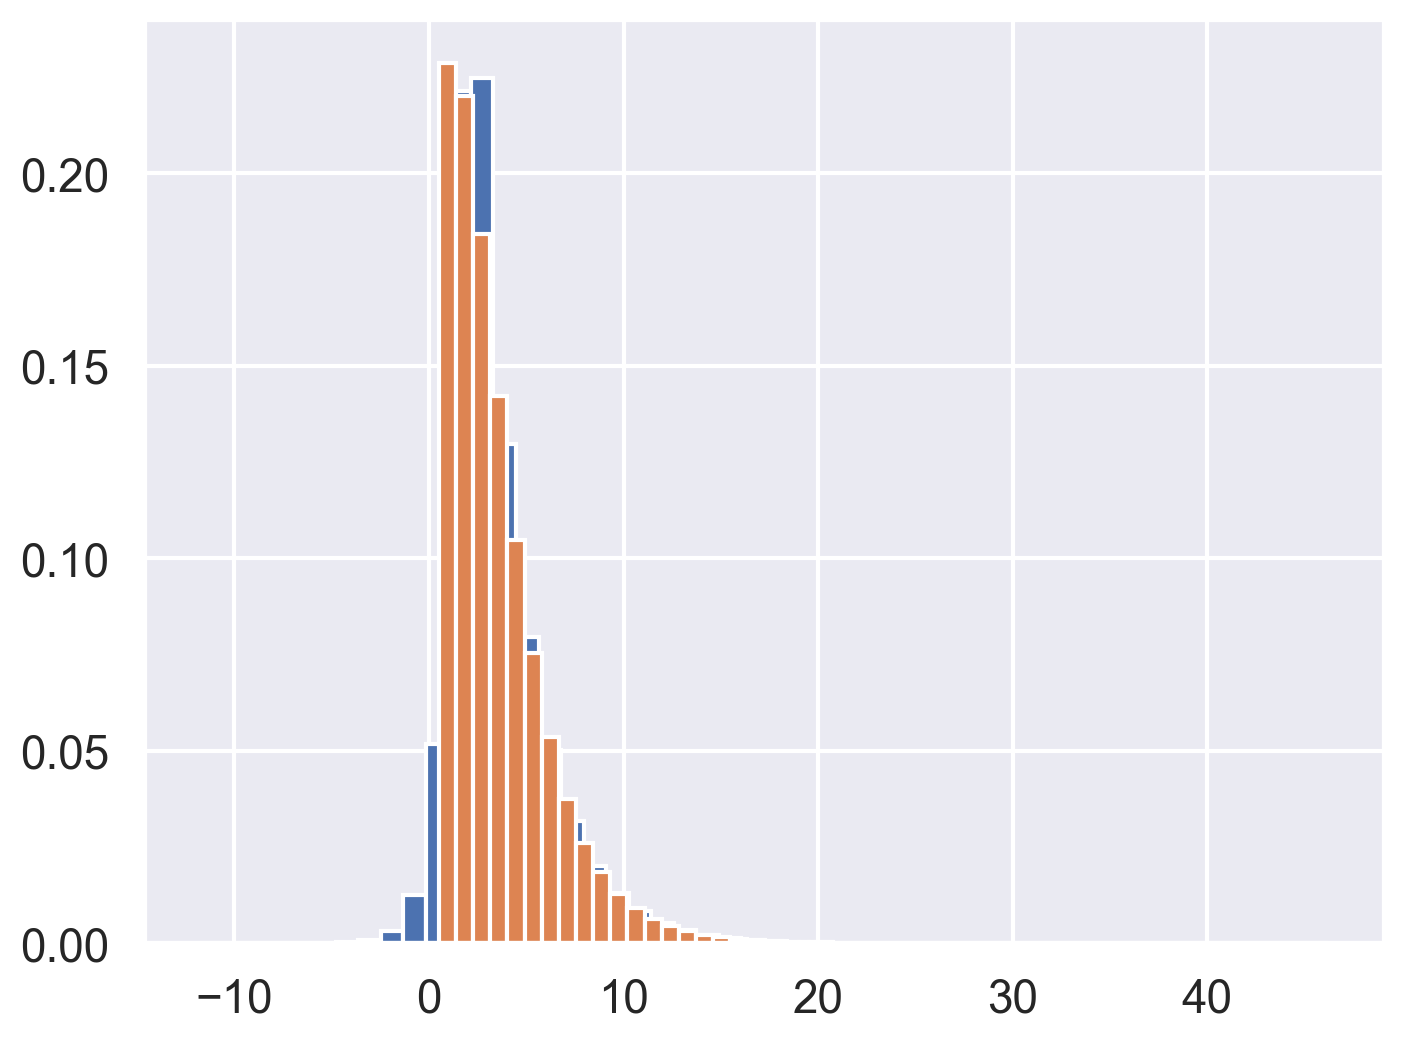

In [125]:
fig, ax = plt.subplots()
ax.hist(X, density=True, bins=50)
ax.hist(S_n, density=True, bins=50)
plt.show()